#**DS-A4: Model Comparison and Calibration Lab.ipynb**
#**Name: Kassahun Azezew Ayidagn**
#**ID: 2026A8002209001**
**GitHub Link: **

**Install libraries and upload datasets from your computer**

In [3]:

# DS-A4: Model Comparison and Calibration Lab
# Step 1: Install libraries and upload datasets from your computer

%pip install -q numpy pandas pillow scikit-image scikit-learn matplotlib

from google.colab import files
from pathlib import Path
import zipfile
import hashlib
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from skimage.metrics import structural_similarity

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Project folders
PROJECT = Path("/content/DS_A4")
DATA_DIR = PROJECT / "data"
RESULTS_DIR = PROJECT / "results"
DIAGNOSTICS_DIR = PROJECT / "diagnostics"
REPORTS_DIR = PROJECT / "reports"

for folder in [
    DATA_DIR, RESULTS_DIR, DIAGNOSTICS_DIR, REPORTS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders created.")
print("Now select DB1_B.zip and DB2_B.zip from your computer.")

# Upload the original archives from your local disk
uploaded = files.upload()

for filename, content in uploaded.items():
    if filename.lower().endswith(".zip"):
        destination = DATA_DIR / Path(filename).name
        destination.write_bytes(content)
        print("Uploaded:", filename)

print("\nAvailable ZIP files:")
for path in DATA_DIR.glob("*.zip"):
    print(path.name, "-", path.stat().st_size, "bytes")

Project folders created.
Now select DB1_B.zip and DB2_B.zip from your computer.


Saving DB1_B.zip to DB1_B.zip
Saving DB2_B.zip to DB2_B.zip
Uploaded: DB1_B.zip
Uploaded: DB2_B.zip

Available ZIP files:
DB2_B.zip - 5523915 bytes
DB1_B.zip - 5616229 bytes


**Extract and inspect the datasets**

In [4]:

from pathlib import Path
import zipfile
import pandas as pd
from PIL import Image
from collections import Counter

# Project folders
PROJECT_DIR = Path("/content/DS_A4")
DATA_DIR = PROJECT_DIR / "data"
EXTRACT_DIR = DATA_DIR / "extracted"
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Find ZIP files uploaded in Step 1
zip_files = list(DATA_DIR.glob("*.zip"))

print("ZIP files found:")
for z in zip_files:
    print(f" - {z.name}")

if not zip_files:
    raise FileNotFoundError(
        "No ZIP files found. Please rerun Step 1 and upload your ZIP files."
    )

# Extract each archive into a separate folder
for zip_path in zip_files:
    dataset_name = zip_path.stem
    output_dir = EXTRACT_DIR / dataset_name
    output_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(output_dir)

    print(f"\nExtracted: {zip_path.name}")
    print(f"Destination: {output_dir}")

# Find image files recursively
image_extensions = {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}
image_records = []

for image_path in EXTRACT_DIR.rglob("*"):
    if image_path.is_file() and image_path.suffix.lower() in image_extensions:
        try:
            with Image.open(image_path) as img:
                image_records.append({
                    "dataset": image_path.relative_to(EXTRACT_DIR).parts[0],
                    "filename": image_path.name,
                    "relative_path": str(image_path.relative_to(PROJECT_DIR)),
                    "width": img.width,
                    "height": img.height,
                    "mode": img.mode,
                    "format": img.format
                })
        except Exception as exc:
            print(f"Could not read {image_path.name}: {exc}")

manifest = pd.DataFrame(image_records)

if manifest.empty:
    raise ValueError("No readable images found. Check the ZIP file contents.")

manifest_path = PROJECT_DIR / "image_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("\n--- Dataset inspection ---")
print("Total readable images:", len(manifest))
print("\nImages per dataset:")
print(manifest.groupby("dataset").size())

print("\nImage dimensions and modes:")
print(
    manifest.groupby(["dataset", "width", "height", "mode"])
    .size()
    .rename("image_count")
    .reset_index()
    .to_string(index=False)
)

print("\nFirst 10 images:")
display(manifest.head(10))

print(f"\nManifest saved to: {manifest_path}")


ZIP files found:
 - DB2_B.zip
 - DB1_B.zip

Extracted: DB2_B.zip
Destination: /content/DS_A4/data/extracted/DB2_B

Extracted: DB1_B.zip
Destination: /content/DS_A4/data/extracted/DB1_B

--- Dataset inspection ---
Total readable images: 160

Images per dataset:
dataset
DB1_B    80
DB2_B    80
dtype: int64

Image dimensions and modes:
dataset  width  height mode  image_count
  DB1_B    300     300    L           80
  DB2_B    256     364    L           80

First 10 images:


,dataset,filename,relative_path,width,height,mode,format
0,DB2_B,109_4.tif,data/extracted/DB2_B/109_4.tif,256,364,L,TIFF
1,DB2_B,104_8.tif,data/extracted/DB2_B/104_8.tif,256,364,L,TIFF
2,DB2_B,110_2.tif,data/extracted/DB2_B/110_2.tif,256,364,L,TIFF
3,DB2_B,101_3.tif,data/extracted/DB2_B/101_3.tif,256,364,L,TIFF
4,DB2_B,101_8.tif,data/extracted/DB2_B/101_8.tif,256,364,L,TIFF
5,DB2_B,103_4.tif,data/extracted/DB2_B/103_4.tif,256,364,L,TIFF
6,DB2_B,110_6.tif,data/extracted/DB2_B/110_6.tif,256,364,L,TIFF
7,DB2_B,104_7.tif,data/extracted/DB2_B/104_7.tif,256,364,L,TIFF
8,DB2_B,104_3.tif,data/extracted/DB2_B/104_3.tif,256,364,L,TIFF
9,DB2_B,102_4.tif,data/extracted/DB2_B/102_4.tif,256,364,L,TIFF



Manifest saved to: /content/DS_A4/image_manifest.csv


**Verify identities and inspect sample images**

Total parsed images: 160
Unique dataset-identity groups: 20

Images per identity:


,dataset,identity,image_count,unique_impressions,impressions
0,DB1_B,101,8,8,"[1, 2, 3, 4, 5, 6, 7, 8]"
1,DB1_B,102,8,8,"[1, 2, 3, 4, 5, 6, 7, 8]"
2,DB1_B,103,8,8,"[1, 2, 3, 4, 5, 6, 7, 8]"
3,DB1_B,104,8,8,"[1, 2, 3, 4, 5, 6, 7, 8]"
4,DB1_B,105,8,8,"[1, 2, 3, 4, 5, 6, 7, 8]"
5,DB1_B,106,8,8,"[1, 2, 3, 4, 5, 6, 7, 8]"
6,DB1_B,107,8,8,"[1, 2, 3, 4, 5, 6, 7, 8]"
7,DB1_B,108,8,8,"[1, 2, 3, 4, 5, 6, 7, 8]"
8,DB1_B,109,8,8,"[1, 2, 3, 4, 5, 6, 7, 8]"
9,DB1_B,110,8,8,"[1, 2, 3, 4, 5, 6, 7, 8]"



Dataset-level identity summary:


,identities,total_images,min_images_per_identity,max_images_per_identity
dataset,,,,
DB1_B,10,80,8,8
DB2_B,10,80,8,8



Duplicate identity/impression records: 0


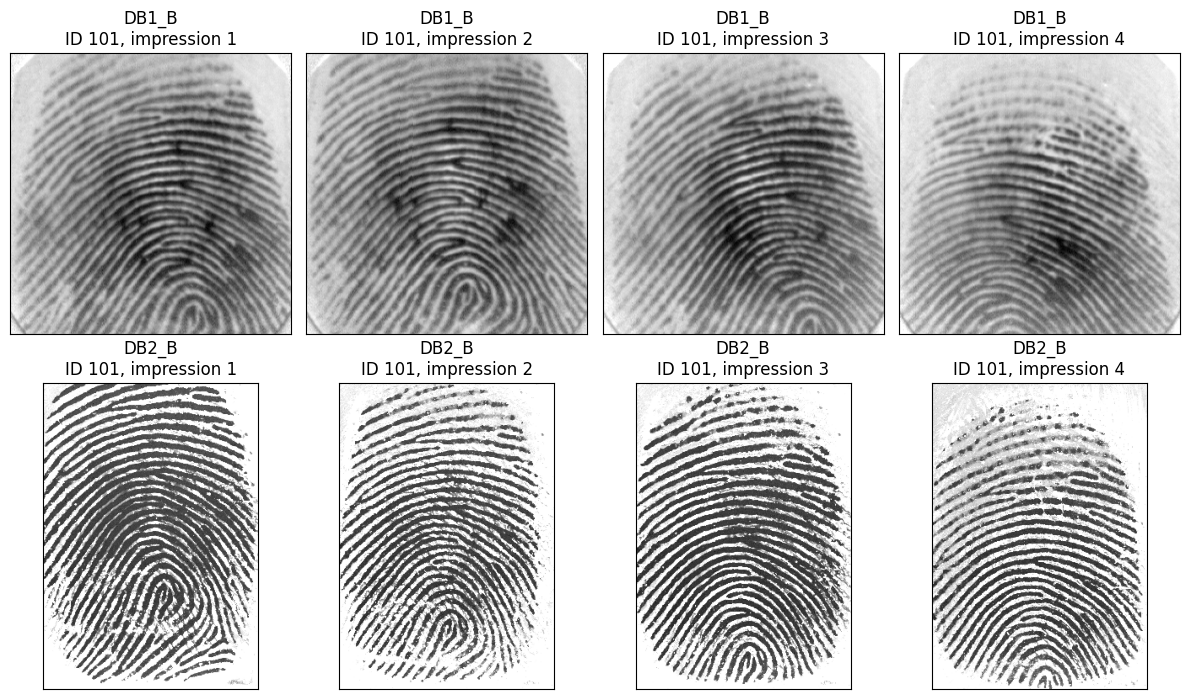


Saved: /content/DS_A4/verified_image_manifest.csv


In [5]:

from pathlib import Path
from collections import defaultdict
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/DS_A4")
EXTRACT_DIR = PROJECT_DIR / "data" / "extracted"

image_extensions = {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}
records = []

# Parse filenames such as 103_6.tif:
# first part = presumed identity; second part = presumed impression
for path in sorted(EXTRACT_DIR.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in image_extensions:
        continue

    parts = path.stem.split("_")

    if len(parts) != 2 or not all(part.isdigit() for part in parts):
        print("Filename needs manual review:", path.name)
        continue

    dataset = path.relative_to(EXTRACT_DIR).parts[0]

    records.append({
        "dataset": dataset,
        "filename": path.name,
        "identity": parts[0],
        "impression": int(parts[1]),
        "path": str(path)
    })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No filenames matched the expected ID_impression pattern.")

# Treat each dataset's identities separately
df["group_id"] = df["dataset"] + "_" + df["identity"]

print("Total parsed images:", len(df))
print("Unique dataset-identity groups:", df["group_id"].nunique())

print("\nImages per identity:")
identity_counts = (
    df.groupby(["dataset", "identity"])
      .agg(
          image_count=("filename", "count"),
          unique_impressions=("impression", "nunique"),
          impressions=("impression", lambda x: sorted(x.tolist()))
      )
      .reset_index()
)
display(identity_counts)

print("\nDataset-level identity summary:")
summary = (
    identity_counts.groupby("dataset")
    .agg(
        identities=("identity", "nunique"),
        total_images=("image_count", "sum"),
        min_images_per_identity=("image_count", "min"),
        max_images_per_identity=("image_count", "max")
    )
)
display(summary)

# Check duplicate identity/impression combinations
duplicates = df.duplicated(
    subset=["dataset", "identity", "impression"], keep=False
)
print("\nDuplicate identity/impression records:", int(duplicates.sum()))

# Save the verified filename-level manifest
df.drop(columns=["path"]).to_csv(
    PROJECT_DIR / "verified_image_manifest.csv", index=False
)

# Display sample images from each dataset
fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for row, dataset in enumerate(sorted(df["dataset"].unique())):
    sample = df[df["dataset"] == dataset].head(4)

    for col in range(4):
        ax = axes[row, col]

        if col < len(sample):
            record = sample.iloc[col]
            with Image.open(record["path"]) as img:
                ax.imshow(img, cmap="gray")

            ax.set_title(
                f"{dataset}\nID {record['identity']}, "
                f"impression {record['impression']}"
            )
        else:
            ax.axis("off")

        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

print("\nSaved:", PROJECT_DIR / "verified_image_manifest.csv")


**Generate genuine and impostor pairs**

In [6]:

from pathlib import Path
from itertools import combinations
import pandas as pd
import numpy as np

PROJECT_DIR = Path("/content/DS_A4")
EXTRACT_DIR = PROJECT_DIR / "data" / "extracted"

SEED = 42
IMPOSTOR_PAIRS_PER_DATASET = 800

rng = np.random.default_rng(SEED)
extensions = {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}

# Rebuild the image manifest
images = []

for path in sorted(EXTRACT_DIR.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in extensions:
        continue

    parts = path.stem.split("_")
    if len(parts) != 2 or not all(p.isdigit() for p in parts):
        continue

    dataset = path.relative_to(EXTRACT_DIR).parts[0]

    images.append({
        "dataset": dataset,
        "identity": parts[0],
        "impression": int(parts[1]),
        "path": str(path)
    })

image_df = pd.DataFrame(images)

if image_df.empty:
    raise ValueError("No valid images found.")

# Ensure all expected impression records are unique
if image_df.duplicated(["dataset", "identity", "impression"]).any():
    raise ValueError("Duplicate identity/impression records detected.")

pair_rows = []

for dataset in sorted(image_df["dataset"].unique()):
    subset = image_df[image_df["dataset"] == dataset]
    identities = sorted(subset["identity"].unique())

    # Genuine pairs: all combinations of impressions within each identity
    for identity in identities:
        group = subset[subset["identity"] == identity].to_dict("records")

        for a, b in combinations(group, 2):
            pair_rows.append({
                "dataset": dataset,
                "identity_a": a["identity"],
                "impression_a": a["impression"],
                "path_a": a["path"],
                "identity_b": b["identity"],
                "impression_b": b["impression"],
                "path_b": b["path"],
                "label": 1,
                "pair_type": "genuine"
            })

    # All possible impostor identity combinations, then sample reproducibly
    impostor_candidates = []

    for identity_a, identity_b in combinations(identities, 2):
        group_a = subset[subset["identity"] == identity_a].to_dict("records")
        group_b = subset[subset["identity"] == identity_b].to_dict("records")

        for a in group_a:
            for b in group_b:
                impostor_candidates.append({
                    "dataset": dataset,
                    "identity_a": a["identity"],
                    "impression_a": a["impression"],
                    "path_a": a["path"],
                    "identity_b": b["identity"],
                    "impression_b": b["impression"],
                    "path_b": b["path"],
                    "label": 0,
                    "pair_type": "impostor"
                })

    n_sample = min(IMPOSTOR_PAIRS_PER_DATASET, len(impostor_candidates))
    selected_indices = rng.choice(
        len(impostor_candidates), size=n_sample, replace=False
    )

    pair_rows.extend(impostor_candidates[i] for i in selected_indices)

pairs_df = pd.DataFrame(pair_rows)

# Stable ordering for reproducibility
pairs_df = pairs_df.sort_values(
    ["dataset", "label", "identity_a", "impression_a",
     "identity_b", "impression_b"]
).reset_index(drop=True)

pairs_path = PROJECT_DIR / "pair_manifest.csv"
pairs_df.to_csv(pairs_path, index=False)

print("Pair manifest saved:", pairs_path)
print("Total pairs:", len(pairs_df))
print("\nPair counts by dataset and type:")
display(
    pairs_df.groupby(["dataset", "pair_type"])
    .size().rename("count").reset_index()
)

print("\nLabel balance:")
display(
    pairs_df["label"].value_counts()
    .rename(index={1: "genuine (1)", 0: "impostor (0)"})
    .rename("count").to_frame()
)

# Basic integrity checks
assert (pairs_df["identity_a"] == pairs_df["identity_b"]).equals(
    pairs_df["label"].eq(1)
), "Pair labels do not match identity comparisons."

assert (pairs_df["dataset"].notna()).all()
assert (pairs_df["path_a"] != pairs_df["path_b"]).all()

print("\nIntegrity checks passed.")
display(pairs_df.head(10))


Pair manifest saved: /content/DS_A4/pair_manifest.csv
Total pairs: 2160

Pair counts by dataset and type:


,dataset,pair_type,count
0,DB1_B,genuine,280
1,DB1_B,impostor,800
2,DB2_B,genuine,280
3,DB2_B,impostor,800



Label balance:


,count
label,
impostor (0),1600
genuine (1),560



Integrity checks passed.


,dataset,identity_a,impression_a,path_a,identity_b,impression_b,path_b,label,pair_type
0,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,103,5,/content/DS_A4/data/extracted/DB1_B/103_5.tif,0,impostor
1,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,104,3,/content/DS_A4/data/extracted/DB1_B/104_3.tif,0,impostor
2,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,104,8,/content/DS_A4/data/extracted/DB1_B/104_8.tif,0,impostor
3,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,105,3,/content/DS_A4/data/extracted/DB1_B/105_3.tif,0,impostor
4,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,105,4,/content/DS_A4/data/extracted/DB1_B/105_4.tif,0,impostor
5,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,105,5,/content/DS_A4/data/extracted/DB1_B/105_5.tif,0,impostor
6,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,105,7,/content/DS_A4/data/extracted/DB1_B/105_7.tif,0,impostor
7,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,105,8,/content/DS_A4/data/extracted/DB1_B/105_8.tif,0,impostor
8,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,106,3,/content/DS_A4/data/extracted/DB1_B/106_3.tif,0,impostor
9,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,106,4,/content/DS_A4/data/extracted/DB1_B/106_4.tif,0,impostor


**Freeze the evaluation protocol**

In [7]:

from pathlib import Path
from itertools import combinations
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold

PROJECT_DIR = Path("/content/DS_A4")
EXTRACT_DIR = PROJECT_DIR / "data" / "extracted"

SEED = 42
N_FOLDS = 5
IMAGE_EXTENSIONS = {".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp"}

# 1. Read the verified images
images = []

for path in sorted(EXTRACT_DIR.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    parts = path.stem.split("_")
    if len(parts) != 2 or not all(p.isdigit() for p in parts):
        continue

    dataset = path.relative_to(EXTRACT_DIR).parts[0]
    images.append({
        "dataset": dataset,
        "identity": parts[0],
        "impression": int(parts[1]),
        "path": str(path)
    })

image_df = pd.DataFrame(images)

if image_df.empty:
    raise ValueError("No valid images found.")

if image_df.duplicated(["dataset", "identity", "impression"]).any():
    raise ValueError("Duplicate image records detected.")

# 2. Assign each identity to one fixed fold, separately per dataset
rng = np.random.RandomState(SEED)
fold_rows = []

for dataset in sorted(image_df["dataset"].unique()):
    identities = sorted(
        image_df.loc[image_df["dataset"] == dataset, "identity"].unique()
    )

    if len(identities) < N_FOLDS:
        raise ValueError(f"Not enough identities in {dataset} for {N_FOLDS} folds.")

    kfold = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

    for fold_id, (_, test_idx) in enumerate(kfold.split(identities)):
        test_ids = {identities[i] for i in test_idx}

        for identity in identities:
            fold_rows.append({
                "dataset": dataset,
                "identity": identity,
                "fold": fold_id,
                "held_out_in_fold": identity in test_ids
            })

fold_df = pd.DataFrame(fold_rows)
fold_map = {
    (r.dataset, r.identity): int(r.fold)
    for r in fold_df.itertuples()
}

# 3. Generate all possible genuine and impostor pairs
pair_rows = []

for dataset in sorted(image_df["dataset"].unique()):
    subset = image_df[image_df["dataset"] == dataset]
    identity_groups = {
        identity: group.to_dict("records")
        for identity, group in subset.groupby("identity")
    }
    identities = sorted(identity_groups)

    for identity in identities:
        group = identity_groups[identity]
        for a, b in combinations(group, 2):
            pair_rows.append({
                "dataset": dataset,
                "identity_a": identity,
                "impression_a": a["impression"],
                "path_a": a["path"],
                "identity_b": identity,
                "impression_b": b["impression"],
                "path_b": b["path"],
                "label": 1
            })

    for identity_a, identity_b in combinations(identities, 2):
        for a in identity_groups[identity_a]:
            for b in identity_groups[identity_b]:
                pair_rows.append({
                    "dataset": dataset,
                    "identity_a": identity_a,
                    "impression_a": a["impression"],
                    "path_a": a["path"],
                    "identity_b": identity_b,
                    "impression_b": b["impression"],
                    "path_b": b["path"],
                    "label": 0
                })

pairs = pd.DataFrame(pair_rows)
pairs["fold_a"] = [
    fold_map[(d, i)] for d, i in zip(pairs["dataset"], pairs["identity_a"])
]
pairs["fold_b"] = [
    fold_map[(d, i)] for d, i in zip(pairs["dataset"], pairs["identity_b"])
]

# 4. Assign each pair per fold:
# test = both identities belong to the held-out fold
# train = neither identity belongs to the held-out fold
# cross-fold pairs are excluded from that fold
fold_summaries = []

for fold_id in range(N_FOLDS):
    test_mask = (pairs["fold_a"] == fold_id) & (pairs["fold_b"] == fold_id)
    train_mask = (pairs["fold_a"] != fold_id) & (pairs["fold_b"] != fold_id)

    pairs[f"split_fold_{fold_id}"] = np.select(
        [test_mask, train_mask],
        ["test", "train"],
        default="excluded"
    )

    for split_name, mask in [
        ("train", train_mask),
        ("test", test_mask)
    ]:
        for label in [0, 1]:
            fold_summaries.append({
                "fold": fold_id,
                "split": split_name,
                "label": label,
                "pair_count": int((mask & (pairs["label"] == label)).sum())
            })

# 5. Save all artifacts
fold_df.to_csv(PROJECT_DIR / "identity_fold_assignments.csv", index=False)
pairs.to_csv(PROJECT_DIR / "all_pairs_frozen_folds.csv", index=False)

summary_df = pd.DataFrame(fold_summaries)
summary_df.to_csv(PROJECT_DIR / "fold_pair_summary.csv", index=False)

protocol = {
    "seed": SEED,
    "n_folds": N_FOLDS,
    "pair_generation": "All genuine and impostor pairs within each dataset",
    "identity_grouping": "Dataset-specific identity",
    "test_rule": "Both pair identities belong to the held-out fold",
    "train_rule": "Neither pair identity belongs to the held-out fold",
    "cross_fold_pairs": "Excluded from that fold",
    "datasets": sorted(image_df["dataset"].unique()),
    "images": int(len(image_df)),
    "identities": int(image_df.groupby(["dataset", "identity"]).ngroups),
    "pairs": int(len(pairs)),
    "warning": (
        "Only 10 identities per dataset; uncertainty and generalization "
        "must be discussed. Threshold calibration requires separate "
        "identity-disjoint validation within the training identities."
    )
}

with open(PROJECT_DIR / "frozen_protocol.json", "w") as f:
    json.dump(protocol, f, indent=2)

print("Frozen protocol saved.")
print(json.dumps(protocol, indent=2))
print("\nPair counts by fold, split, and label (0=impostor, 1=genuine):")
display(summary_df)

print("\nIdentity assignment:")
display(fold_df.sort_values(["dataset", "fold", "identity"]))

print("\nFiles saved:")
for name in [
    "identity_fold_assignments.csv",
    "all_pairs_frozen_folds.csv",
    "fold_pair_summary.csv",
    "frozen_protocol.json"
]:
    print(" -", PROJECT_DIR / name)


Frozen protocol saved.
{
  "seed": 42,
  "n_folds": 5,
  "pair_generation": "All genuine and impostor pairs within each dataset",
  "identity_grouping": "Dataset-specific identity",
  "test_rule": "Both pair identities belong to the held-out fold",
  "train_rule": "Neither pair identity belongs to the held-out fold",
  "cross_fold_pairs": "Excluded from that fold",
  "datasets": [
    "DB1_B",
    "DB2_B"
  ],
  "images": 160,
  "identities": 20,
  "pairs": 6320,
  "warning": "Only 10 identities per dataset; uncertainty and generalization must be discussed. Threshold calibration requires separate identity-disjoint validation within the training identities."
}

Pair counts by fold, split, and label (0=impostor, 1=genuine):


,fold,split,label,pair_count
0,0,train,0,5760
1,0,train,1,560
2,0,test,0,0
3,0,test,1,0
4,1,train,0,5760
5,1,train,1,560
6,1,test,0,0
7,1,test,1,0
8,2,train,0,5760
9,2,train,1,560



Identity assignment:


,dataset,identity,fold,held_out_in_fold
0,DB1_B,101,0,False
1,DB1_B,102,0,True
2,DB1_B,103,0,False
3,DB1_B,104,0,False
4,DB1_B,105,0,False
...,...,...,...,...
95,DB2_B,106,4,False
96,DB2_B,107,4,True
97,DB2_B,108,4,False
98,DB2_B,109,4,False



Files saved:
 - /content/DS_A4/identity_fold_assignments.csv
 - /content/DS_A4/all_pairs_frozen_folds.csv
 - /content/DS_A4/fold_pair_summary.csv
 - /content/DS_A4/frozen_protocol.json


**Fix the identity-fold assignments**

In [9]:


import pandas as pd
from sklearn.model_selection import KFold
from pathlib import Path

# Project paths
BASE_DIR = Path("/content/DS_A4")
MANIFEST_PATH = BASE_DIR / "verified_image_manifest.csv"

# Load verified image manifest
manifest = pd.read_csv(MANIFEST_PATH)

# Normalize identity values to strings
manifest["identity"] = manifest["identity"].astype(str)
manifest["dataset"] = manifest["dataset"].astype(str)

SEED = 42
N_SPLITS = 5

fold_records = []

# Assign each identity to exactly ONE test fold
for dataset in sorted(manifest["dataset"].unique()):
    identities = sorted(
        manifest.loc[
            manifest["dataset"] == dataset, "identity"
        ].unique()
    )

    assert len(identities) == 10, (
        f"Expected 10 identities in {dataset}, "
        f"found {len(identities)}"
    )

    splitter = KFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=SEED
    )

    # IMPORTANT: append only identities in this fold's test split
    for fold_id, (_, test_indices) in enumerate(
        splitter.split(identities)
    ):
        for idx in test_indices:
            fold_records.append({
                "dataset": dataset,
                "identity": identities[idx],
                "fold": fold_id
            })

folds = pd.DataFrame(fold_records)

# Validate: every dataset-identity occurs exactly once
assert not folds.duplicated(["dataset", "identity"]).any()
assert folds.groupby("dataset")["identity"].nunique().eq(10).all()
assert folds.groupby("dataset").size().eq(10).all()

# Save the corrected assignment
folds.to_csv(BASE_DIR / "identity_folds.csv", index=False)

print("Identity-fold assignments created successfully.")
print("\nIdentities per fold:")
print(
    folds.groupby(["dataset", "fold"])["identity"]
    .agg(["count", lambda x: ", ".join(sorted(x))])
    .to_string()
)

print("\nValidation passed: each identity belongs to exactly one fold.")


Identity-fold assignments created successfully.

Identities per fold:
              count <lambda_0>
dataset fold                  
DB1_B   0         2   102, 109
        1         2   101, 106
        2         2   103, 108
        3         2   105, 110
        4         2   104, 107
DB2_B   0         2   102, 109
        1         2   101, 106
        2         2   103, 108
        3         2   105, 110
        4         2   104, 107

Validation passed: each identity belongs to exactly one fold.


In [10]:

pairs_path = BASE_DIR / "all_pairs_frozen_folds.csv"

if not pairs_path.exists():
    print("Pair file not found:", pairs_path)
    print("Please check the filename used in your earlier pair-generation cell.")
else:
    pairs = pd.read_csv(pairs_path)
    print("Pair-manifest columns:")
    print(pairs.columns.tolist())
    print("\nFirst five rows:")
    display(pairs.head())


Pair-manifest columns:
['dataset', 'identity_a', 'impression_a', 'path_a', 'identity_b', 'impression_b', 'path_b', 'label', 'fold_a', 'fold_b', 'split_fold_0', 'split_fold_1', 'split_fold_2', 'split_fold_3', 'split_fold_4']

First five rows:


,dataset,identity_a,impression_a,path_a,identity_b,impression_b,path_b,label,fold_a,fold_b,split_fold_0,split_fold_1,split_fold_2,split_fold_3,split_fold_4
0,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,101,2,/content/DS_A4/data/extracted/DB1_B/101_2.tif,1,4,4,train,train,train,train,test
1,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,101,3,/content/DS_A4/data/extracted/DB1_B/101_3.tif,1,4,4,train,train,train,train,test
2,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,101,4,/content/DS_A4/data/extracted/DB1_B/101_4.tif,1,4,4,train,train,train,train,test
3,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,101,5,/content/DS_A4/data/extracted/DB1_B/101_5.tif,1,4,4,train,train,train,train,test
4,DB1_B,101,1,/content/DS_A4/data/extracted/DB1_B/101_1.tif,101,6,/content/DS_A4/data/extracted/DB1_B/101_6.tif,1,4,4,train,train,train,train,test


**Correct the validation and save the folds**

In [12]:


import pandas as pd
from pathlib import Path

BASE_DIR = Path("/content/DS_A4")

pairs = pd.read_csv(BASE_DIR / "all_pairs_frozen_folds.csv")
folds = pd.read_csv(BASE_DIR / "identity_folds.csv")

# Normalize identifiers
pairs["dataset"] = pairs["dataset"].astype(str)
folds["dataset"] = folds["dataset"].astype(str)

for col in ["identity_a", "identity_b"]:
    pairs[col] = pd.to_numeric(pairs[col]).astype(int).astype(str)

folds["identity"] = (
    pd.to_numeric(folds["identity"]).astype(int).astype(str)
)

# Validate unique identity assignments
assert not folds.duplicated(["dataset", "identity"]).any()

lookup = {
    (r.dataset, r.identity): int(r.fold)
    for r in folds.itertuples(index=False)
}

pairs["fold_a"] = [
    lookup[(d, i)]
    for d, i in zip(pairs["dataset"], pairs["identity_a"])
]
pairs["fold_b"] = [
    lookup[(d, i)]
    for d, i in zip(pairs["dataset"], pairs["identity_b"])
]

# Verify labels against identity equality
same_identity = (
    pairs["identity_a"].eq(pairs["identity_b"])
    & pairs["dataset"].notna()
)
genuine_label = pairs["label"].eq(1)

assert (same_identity == genuine_label).all(), (
    "Pair labels do not match the identity fields. "
    "Inspect the mismatched rows before proceeding."
)

# Rebuild train/test/excluded splits
for fold_id in range(5):
    a_held_out = pairs["fold_a"].eq(fold_id)
    b_held_out = pairs["fold_b"].eq(fold_id)

    col = f"split_fold_{fold_id}"
    pairs[col] = "excluded"
    pairs.loc[~a_held_out & ~b_held_out, col] = "train"
    pairs.loc[a_held_out & b_held_out, col] = "test"

# Show counts before saving
rows = []
for fold_id in range(5):
    col = f"split_fold_{fold_id}"
    for split in ["train", "test", "excluded"]:
        subset = pairs.loc[pairs[col].eq(split)]
        rows.append({
            "fold": fold_id,
            "split": split,
            "total": len(subset),
            "genuine": int(subset["label"].eq(1).sum()),
            "impostor": int(subset["label"].eq(0).sum())
        })

summary = pd.DataFrame(rows)
display(summary)

# Check each fold's identity-disjoint split
for fold_id in range(5):
    col = f"split_fold_{fold_id}"
    train_ids = set(pairs.loc[
        pairs[col].eq("train"), "identity_a"
    ]) | set(pairs.loc[
        pairs[col].eq("train"), "identity_b"
    ])
    test_ids = set(pairs.loc[
        pairs[col].eq("test"), "identity_a"
    ]) | set(pairs.loc[
        pairs[col].eq("test"), "identity_b"
    ])
    assert train_ids.isdisjoint(test_ids), (
        f"Identity leakage detected in fold {fold_id}"
    )

out_path = BASE_DIR / "all_pairs_corrected_folds.csv"
pairs.to_csv(out_path, index=False)

print("Saved corrected pair manifest:", out_path)
print("Pair-label and identity checks passed.")


,fold,split,total,genuine,impostor
0,0,train,4032,448,3584
1,0,test,240,112,128
2,0,excluded,2048,0,2048
3,1,train,4032,448,3584
4,1,test,240,112,128
5,1,excluded,2048,0,2048
6,2,train,4032,448,3584
7,2,test,240,112,128
8,2,excluded,2048,0,2048
9,3,train,4032,448,3584


Saved corrected pair manifest: /content/DS_A4/all_pairs_corrected_folds.csv
Pair-label and identity checks passed.


**Verify the pair counts and dataset composition**

In [13]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path("/content/DS_A4")
pairs = pd.read_csv(BASE_DIR / "all_pairs_corrected_folds.csv")

print("Total pairs:", len(pairs))
print("\nLabels (0 = impostor, 1 = genuine):")
display(pairs["label"].value_counts().sort_index().rename("count").to_frame())

print("\nPairs by dataset and label:")
display(
    pairs.groupby(["dataset", "label"])
    .size()
    .unstack(fill_value=0)
)

print("\nDistinct identities per dataset:")
display(
    pairs.groupby("dataset")["identity_a"]
    .nunique()
    .rename("unique identity_a")
    .to_frame()
)

print("\nTest pairs in each fold:")
for fold_id in range(5):
    col = f"split_fold_{fold_id}"
    test = pairs[pairs[col] == "test"]
    print(
        f"Fold {fold_id}: total={len(test)}, "
        f"genuine={(test['label'] == 1).sum()}, "
        f"impostor={(test['label'] == 0).sum()}"
    )


Total pairs: 6320

Labels (0 = impostor, 1 = genuine):


,count
label,
0,5760
1,560



Pairs by dataset and label:


label,0,1
dataset,,
DB1_B,2880,280
DB2_B,2880,280



Distinct identities per dataset:


,unique identity_a
dataset,
DB1_B,10
DB2_B,10



Test pairs in each fold:
Fold 0: total=240, genuine=112, impostor=128
Fold 1: total=240, genuine=112, impostor=128
Fold 2: total=240, genuine=112, impostor=128
Fold 3: total=240, genuine=112, impostor=128
Fold 4: total=240, genuine=112, impostor=128


**Extract image-pair features**

In [14]:

# Step 6B: Feature extraction
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from skimage.metrics import structural_similarity
from tqdm.auto import tqdm

BASE_DIR = Path("/content/DS_A4")
INPUT_PATH = BASE_DIR / "all_pairs_corrected_folds.csv"
OUTPUT_PATH = BASE_DIR / "pair_features.csv"

pairs = pd.read_csv(INPUT_PATH)

# Cache resized images: each unique image is loaded only once
image_cache = {}

def load_image(path, size=(64, 64)):
    path = str(path)

    if path not in image_cache:
        with Image.open(path) as img:
            img = img.convert("L")
            img = img.resize(size, Image.Resampling.LANCZOS)
            arr = np.asarray(img, dtype=np.float32) / 255.0

        image_cache[path] = arr

    return image_cache[path]

def extract_pair_features(path_a, path_b):
    img_a = load_image(path_a)
    img_b = load_image(path_b)

    # 1. Mean absolute pixel difference: lower means more similar
    mean_abs_diff = float(np.mean(np.abs(img_a - img_b)))

    # 2. Pixel correlation
    a_flat = img_a.ravel()
    b_flat = img_b.ravel()

    if np.std(a_flat) < 1e-8 or np.std(b_flat) < 1e-8:
        pixel_correlation = 0.0
    else:
        pixel_correlation = float(np.corrcoef(a_flat, b_flat)[0, 1])

    if not np.isfinite(pixel_correlation):
        pixel_correlation = 0.0

    # 3. Structural similarity index
    ssim_value = float(
        structural_similarity(img_a, img_b, data_range=1.0)
    )

    return mean_abs_diff, pixel_correlation, ssim_value

feature_rows = []

for row in tqdm(
    pairs.itertuples(index=False),
    total=len(pairs),
    desc="Extracting pair features"
):
    mad, corr, ssim = extract_pair_features(
        row.path_a, row.path_b
    )

    feature_rows.append({
        "mean_abs_diff": mad,
        "pixel_correlation": corr,
        "ssim": ssim,
        "dataset_DB2_B": int(row.dataset == "DB2_B")
    })

features = pd.DataFrame(feature_rows)

# Preserve labels and split definitions for later model evaluation
metadata_cols = [
    "dataset", "identity_a", "identity_b",
    "label", "fold_a", "fold_b"
] + [f"split_fold_{i}" for i in range(5)]

result = pd.concat(
    [
        pairs[metadata_cols].reset_index(drop=True),
        features.reset_index(drop=True)
    ],
    axis=1
)

assert len(result) == len(pairs)
assert result[
    ["mean_abs_diff", "pixel_correlation", "ssim"]
].notna().all().all()

result.to_csv(OUTPUT_PATH, index=False)

print("\nFeature extraction complete.")
print("Unique images cached:", len(image_cache))
print("Pair records:", len(result))
print("Features:", features.columns.tolist())
print("Saved to:", OUTPUT_PATH)

display(result.head())
display(result[features.columns].describe().T)


Extracting pair features:   0%|          | 0/6320 [00:00<?, ?it/s]


Feature extraction complete.
Unique images cached: 160
Pair records: 6320
Features: ['mean_abs_diff', 'pixel_correlation', 'ssim', 'dataset_DB2_B']
Saved to: /content/DS_A4/pair_features.csv


,dataset,identity_a,identity_b,label,fold_a,fold_b,split_fold_0,split_fold_1,split_fold_2,split_fold_3,split_fold_4,mean_abs_diff,pixel_correlation,ssim,dataset_DB2_B
0,DB1_B,101,101,1,1,1,train,test,train,train,train,0.081972,0.681563,0.255064,0
1,DB1_B,101,101,1,1,1,train,test,train,train,train,0.072390,0.759555,0.245965,0
2,DB1_B,101,101,1,1,1,train,test,train,train,train,0.097993,0.693573,0.244919,0
3,DB1_B,101,101,1,1,1,train,test,train,train,train,0.087577,0.595320,0.159662,0
4,DB1_B,101,101,1,1,1,train,test,train,train,train,0.088793,0.546992,0.188999,0


,count,mean,std,min,25%,50%,75%,max
mean_abs_diff,6320.0,0.138545,0.046037,0.025206,0.100905,0.138832,0.169190,0.322330
pixel_correlation,6320.0,0.383759,0.203293,-0.391363,0.251683,0.399150,0.533077,0.924542
ssim,6320.0,0.173795,0.091568,-0.082521,0.095045,0.155105,0.244830,0.565583
dataset_DB2_B,6320.0,0.500000,0.500040,0.000000,0.000000,0.500000,1.000000,1.000000


#**Run the experiment**

In [15]:

# Step 7A: Five-fold model comparison
import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    accuracy_score
)

BASE_DIR = Path("/content/DS_A4")
RESULTS_DIR = BASE_DIR / "raw_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = BASE_DIR / "pair_features.csv"
df = pd.read_csv(DATA_PATH)

FEATURES = [
    "mean_abs_diff",
    "pixel_correlation",
    "ssim",
    "dataset_DB2_B"
]

required = FEATURES + ["label"] + [
    f"split_fold_{i}" for i in range(5)
]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing columns: {missing}"
assert df[FEATURES].notna().all().all()
assert df["label"].isin([0, 1]).all()

X = df[FEATURES].astype(float)
y = df["label"].astype(int)

models = {
    "DummyPrior": DummyClassifier(strategy="prior"),

    "LogisticRegression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    ),

    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
}

def expected_calibration_error(y_true, probabilities, n_bins=10):
    """Unweighted ECE; interpret cautiously under prior shift."""
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.minimum(
        np.digitize(probabilities, edges[1:-1]),
        n_bins - 1
    )

    ece = 0.0
    for bin_id in range(n_bins):
        mask = bin_ids == bin_id
        if mask.any():
            confidence = probabilities[mask].mean()
            observed_rate = y_true[mask].mean()
            ece += mask.mean() * abs(confidence - observed_rate)

    return float(ece)

prediction_records = []
metric_records = []

for fold_id in range(5):
    split_col = f"split_fold_{fold_id}"

    train_mask = df[split_col].eq("train")
    test_mask = df[split_col].eq("test")

    train_idx = np.flatnonzero(train_mask.to_numpy())
    test_idx = np.flatnonzero(test_mask.to_numpy())

    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

    print(
        f"Fold {fold_id}: "
        f"train={len(train_idx)}, test={len(test_idx)}, "
        f"train positives={int(y_train.sum())}, "
        f"test positives={int(y_test.sum())}"
    )

    assert len(train_idx) > 0 and len(test_idx) > 0
    assert y_train.nunique() == 2
    assert y_test.nunique() == 2

    for model_name, prototype in models.items():
        model = prototype
        model.fit(X_train, y_train)
        probabilities = model.predict_proba(X_test)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)

        # Save individual test predictions
        for local_i, global_i in enumerate(test_idx):
            prediction_records.append({
                "fold": fold_id,
                "row_index": int(global_i),
                "model": model_name,
                "y_true": int(y_test.iloc[local_i]),
                "probability": float(probabilities[local_i]),
                "prediction_at_0_5": int(predictions[local_i]),
                "dataset": str(df.iloc[global_i]["dataset"])
            })

        metric_records.append({
            "fold": fold_id,
            "model": model_name,
            "n_test": len(y_test),
            "positive_rate": float(y_test.mean()),
            "accuracy_at_0_5": accuracy_score(y_test, predictions),
            "roc_auc": roc_auc_score(y_test, probabilities),
            "pr_auc_average_precision": average_precision_score(
                y_test, probabilities
            ),
            "brier_score": brier_score_loss(y_test, probabilities),
            "ece_10_bins": expected_calibration_error(
                y_test, probabilities
            )
        })

predictions_df = pd.DataFrame(prediction_records)
metrics_df = pd.DataFrame(metric_records)

pred_path = RESULTS_DIR / "model_predictions.csv"
metrics_path = RESULTS_DIR / "fold_metrics.csv"

predictions_df.to_csv(pred_path, index=False)
metrics_df.to_csv(metrics_path, index=False)

# Summarize fold-level results; show variability, not only the mean
summary = (
    metrics_df.groupby("model")
    .agg({
        "roc_auc": ["mean", "std"],
        "pr_auc_average_precision": ["mean", "std"],
        "brier_score": ["mean", "std"],
        "ece_10_bins": ["mean", "std"],
        "accuracy_at_0_5": ["mean", "std"]
    })
    .round(4)
)

print("\nFOLD-LEVEL METRICS:")
display(metrics_df.round(4))

print("\nMEAN AND STANDARD DEVIATION ACROSS FOLDS:")
display(summary)

print("\nSaved predictions:", pred_path)
print("Saved fold metrics:", metrics_path)


Fold 0: train=4032, test=240, train positives=448, test positives=112
Fold 1: train=4032, test=240, train positives=448, test positives=112
Fold 2: train=4032, test=240, train positives=448, test positives=112
Fold 3: train=4032, test=240, train positives=448, test positives=112
Fold 4: train=4032, test=240, train positives=448, test positives=112

FOLD-LEVEL METRICS:


,fold,model,n_test,positive_rate,accuracy_at_0_5,roc_auc,pr_auc_average_precision,brier_score,ece_10_bins
0,0,DummyPrior,240,0.4667,0.5333,0.5000,0.4667,0.3753,0.3556
1,0,LogisticRegression,240,0.4667,0.6792,0.6722,0.7177,0.2485,0.1911
2,0,RandomForest,240,0.4667,0.6875,0.6680,0.7119,0.2601,0.2037
3,0,HistGradientBoosting,240,0.4667,0.6958,0.6707,0.7128,0.2526,0.2021
4,1,DummyPrior,240,0.4667,0.5333,0.5000,0.4667,0.3753,0.3556
5,1,LogisticRegression,240,0.4667,0.5708,0.7691,0.7954,0.3271,0.3507
6,1,RandomForest,240,0.4667,0.6250,0.6794,0.6999,0.2947,0.2734
7,1,HistGradientBoosting,240,0.4667,0.6125,0.7503,0.7572,0.2956,0.2987
8,2,DummyPrior,240,0.4667,0.5333,0.5000,0.4667,0.3753,0.3556
9,2,LogisticRegression,240,0.4667,0.5417,0.6681,0.6955,0.3189,0.3081



MEAN AND STANDARD DEVIATION ACROSS FOLDS:


roc_auc         pr_auc_average_precision          \
                        mean     std                     mean     std   
model                                                                   
DummyPrior            0.5000  0.0000                   0.4667  0.0000   
HistGradientBoosting  0.7494  0.1123                   0.7650  0.1134   
LogisticRegression    0.7542  0.0937                   0.7856  0.0863   
RandomForest          0.7223  0.0945                   0.7455  0.1065   

                     brier_score         ece_10_bins         accuracy_at_0_5  \
                            mean     std        mean     std            mean   
model                                                                          
DummyPrior                0.3753  0.0000      0.3556  0.0000          0.5333   
HistGradientBoosting      0.2791  0.0367      0.2801  0.0451          0.6333   
LogisticRegression        0.2905  0.0356      0.2958  0.0609          0.5950   
RandomForest              0.2759  0.0398      0.2675  0.0395          0.6450   

                              
                         std  
model                         
DummyPrior            0.0000  
HistGradientBoosting  0.0499  
LogisticRegression    0.0543  
RandomForest          0.0571


Saved predictions: /content/DS_A4/raw_results/model_predictions.csv
Saved fold metrics: /content/DS_A4/raw_results/fold_metrics.csv


**evaluation curves**

Models: ['DummyPrior', 'HistGradientBoosting', 'LogisticRegression', 'RandomForest']
Prediction rows: 4800


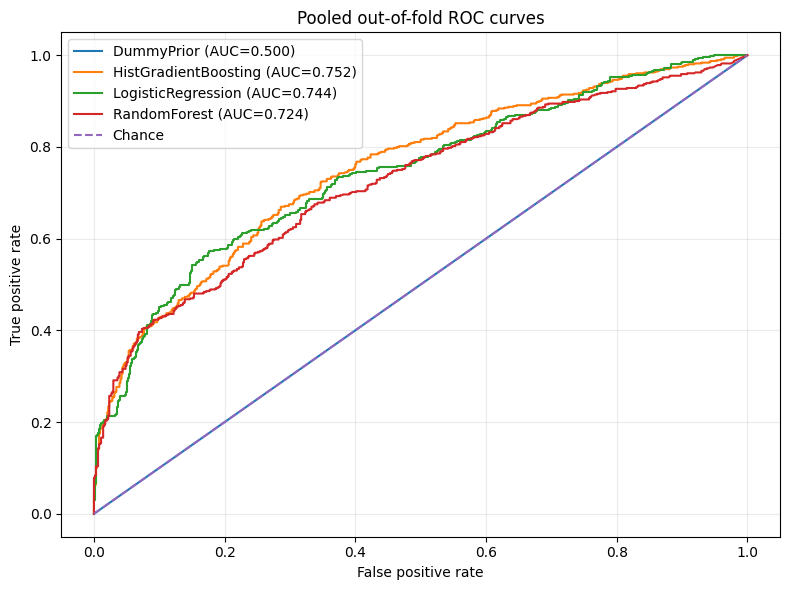

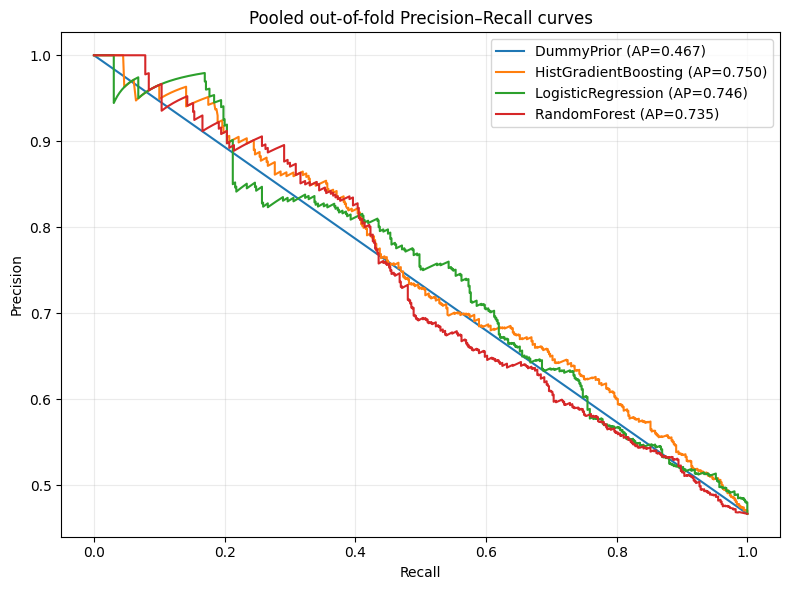

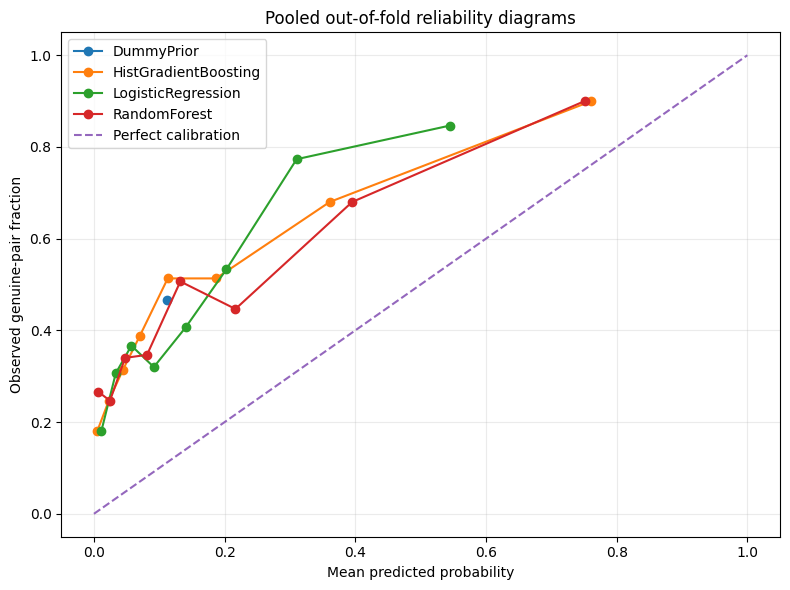

Plots saved in: /content/DS_A4/raw_results


In [16]:

# Step 8A: Evaluation and calibration plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

BASE_DIR = Path("/content/DS_A4")
RESULTS_DIR = BASE_DIR / "raw_results"
PRED_PATH = RESULTS_DIR / "model_predictions.csv"

pred = pd.read_csv(PRED_PATH)

required = {
    "fold", "model", "y_true", "probability",
    "prediction_at_0_5", "dataset"
}
assert required.issubset(pred.columns)

models = sorted(pred["model"].unique())
print("Models:", models)
print("Prediction rows:", len(pred))

# One out-of-fold prediction per model for each test pair
for model in models:
    part = pred[pred["model"] == model]
    assert part["row_index"].is_unique, (
        f"Duplicate test-pair predictions for {model}"
    )

# ROC curves
plt.figure(figsize=(8, 6))
for model in models:
    part = pred[pred["model"] == model]
    fpr, tpr, _ = roc_curve(part["y_true"], part["probability"])
    auc = roc_auc_score(part["y_true"], part["probability"])
    plt.plot(fpr, tpr, label=f"{model} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Pooled out-of-fold ROC curves")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "roc_curves.png", dpi=200)
plt.show()

# Precision–Recall curves
plt.figure(figsize=(8, 6))
for model in models:
    part = pred[pred["model"] == model]
    precision, recall, _ = precision_recall_curve(
        part["y_true"], part["probability"]
    )
    ap = average_precision_score(
        part["y_true"], part["probability"]
    )
    plt.plot(recall, precision, label=f"{model} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Pooled out-of-fold Precision–Recall curves")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "pr_curves.png", dpi=200)
plt.show()

# Reliability diagrams
plt.figure(figsize=(8, 6))
for model in models:
    part = pred[pred["model"] == model]
    observed, predicted = calibration_curve(
        part["y_true"],
        part["probability"],
        n_bins=8,
        strategy="quantile"
    )
    plt.plot(predicted, observed, marker="o", label=model)

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed genuine-pair fraction")
plt.title("Pooled out-of-fold reliability diagrams")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "reliability_diagrams.png", dpi=200)
plt.show()

print("Plots saved in:", RESULTS_DIR)


**uncertainty intervals**

In [19]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score

BASE_DIR = Path("/content/DS_A4")
RESULTS_DIR = BASE_DIR / "raw_results"

pred = pd.read_csv(RESULTS_DIR / "model_predictions.csv")
pairs = pd.read_csv(BASE_DIR / "all_pairs_corrected_folds.csv")

# Keep only metadata needed for identity-cluster analysis.
meta = pairs[
    ["dataset", "identity_a", "identity_b"]
].copy()
meta["row_index"] = np.arange(len(meta))

# Remove overlapping metadata columns before merging.
pred = pred.drop(
    columns=["dataset", "identity_a", "identity_b"],
    errors="ignore"
)

pred = pred.merge(
    meta,
    on="row_index",
    how="left",
    validate="many_to_one"
)

required = {
    "model", "y_true", "probability",
    "dataset", "identity_a", "identity_b"
}
missing = required - set(pred.columns)
assert not missing, f"Missing columns after merge: {missing}"
assert pred["dataset"].notna().all()

# Create dataset-specific identity cluster IDs.
pred["cluster_a"] = (
    pred["dataset"].astype(str) + "_" +
    pred["identity_a"].astype(str)
)
pred["cluster_b"] = (
    pred["dataset"].astype(str) + "_" +
    pred["identity_b"].astype(str)
)

rng = np.random.default_rng(42)
N_BOOT = 1000
records = []

for model in sorted(pred["model"].unique()):
    part = pred[pred["model"] == model].copy()

    original_auc = roc_auc_score(
        part["y_true"], part["probability"]
    )

    clusters = sorted(
        set(part["cluster_a"]) | set(part["cluster_b"])
    )
    bootstrap_aucs = []

    for _ in range(N_BOOT):
        sampled = rng.choice(
            clusters, size=len(clusters), replace=True
        )
        multiplicity = pd.Series(sampled).value_counts().to_dict()

        weights = np.array([
            multiplicity.get(a, 0) * multiplicity.get(b, 0)
            for a, b in zip(part["cluster_a"], part["cluster_b"])
        ])

        keep = weights > 0
        if not keep.any():
            continue

        yb = part.loc[keep, "y_true"].to_numpy()
        pb = part.loc[keep, "probability"].to_numpy()
        wb = weights[keep]

        if len(np.unique(yb)) < 2:
            continue

        try:
            bootstrap_aucs.append(
                roc_auc_score(yb, pb, sample_weight=wb)
            )
        except ValueError:
            continue

    if len(bootstrap_aucs) >= 100:
        low, high = np.percentile(
            bootstrap_aucs, [2.5, 97.5]
        )
    else:
        low, high = np.nan, np.nan

    records.append({
        "model": model,
        "pooled_oof_roc_auc": original_auc,
        "bootstrap_95_ci_low": low,
        "bootstrap_95_ci_high": high,
        "valid_bootstrap_replicates": len(bootstrap_aucs)
    })

ci_df = pd.DataFrame(records)
out_path = RESULTS_DIR / "roc_auc_cluster_bootstrap.csv"
ci_df.to_csv(out_path, index=False)

display(ci_df.round(4))
print("Saved:", out_path)



,model,pooled_oof_roc_auc,bootstrap_95_ci_low,bootstrap_95_ci_high,valid_bootstrap_replicates
0,DummyPrior,0.5000,0.5000,0.5000,1000
1,HistGradientBoosting,0.7523,0.5923,0.8907,998
2,LogisticRegression,0.7437,0.5421,0.9146,1000
3,RandomForest,0.7243,0.5745,0.8559,999


Saved: /content/DS_A4/raw_results/roc_auc_cluster_bootstrap.csv


**evaluation summary**

In [20]:

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    brier_score_loss
)

rows = []
for model, part in pred.groupby("model"):
    rows.append({
        "model": model,
        "n_oof_pairs": len(part),
        "genuine_rate": part["y_true"].mean(),
        "roc_auc": roc_auc_score(
            part["y_true"], part["probability"]
        ),
        "average_precision": average_precision_score(
            part["y_true"], part["probability"]
        ),
        "brier_score": brier_score_loss(
            part["y_true"], part["probability"]
        )
    })

pooled_summary = pd.DataFrame(rows).sort_values(
    "roc_auc", ascending=False
)
display(pooled_summary.round(4))

pooled_summary.to_csv(
    RESULTS_DIR / "pooled_oof_summary.csv", index=False
)
print("Saved pooled summary.")


,model,n_oof_pairs,genuine_rate,roc_auc,average_precision,brier_score
1,HistGradientBoosting,1200,0.4667,0.7523,0.7503,0.2791
2,LogisticRegression,1200,0.4667,0.7437,0.7459,0.2905
3,RandomForest,1200,0.4667,0.7243,0.7349,0.2759
0,DummyPrior,1200,0.4667,0.5000,0.4667,0.3753


Saved pooled summary.


In [21]:

# STEP 8C: Pooled out-of-fold (OOF) metrics

import os
import pandas as pd
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

BASE_DIR = "/content/DS_A4"
RESULTS_DIR = os.path.join(BASE_DIR, "raw_results")

pred_path = os.path.join(RESULTS_DIR, "model_predictions.csv")
assert os.path.exists(pred_path), (
    f"Predictions file not found: {pred_path}. "
    "Check that Step 7A completed successfully."
)

pred = pd.read_csv(pred_path)

required = {"model", "y_true", "probability"}
missing = required - set(pred.columns)
assert not missing, f"Missing columns: {missing}"

pred["y_true"] = pd.to_numeric(pred["y_true"], errors="raise")
pred["probability"] = pd.to_numeric(
    pred["probability"], errors="raise"
)

assert pred["probability"].between(0, 1).all(), (
    "Some predicted probabilities are outside [0, 1]."
)

rows = []

for model_name, group in pred.groupby("model"):
    y = group["y_true"].astype(int)
    p = group["probability"]

    rows.append({
        "model": model_name,
        "n_oof_pairs": len(group),
        "genuine_rate": y.mean(),
        "roc_auc": (
            roc_auc_score(y, p) if y.nunique() == 2 else float("nan")
        ),
        "average_precision": average_precision_score(y, p),
        "brier_score": brier_score_loss(y, p)
    })

pooled_summary = pd.DataFrame(rows).sort_values(
    "roc_auc", ascending=False
)

output_path = os.path.join(
    RESULTS_DIR, "pooled_oof_summary.csv"
)
pooled_summary.to_csv(output_path, index=False)

print("Pooled OOF metrics:")
display(pooled_summary.round(4))

print(f"\nSaved to: {output_path}")
print("\nNote: these pooled metrics describe the available held-out")
print("pairs, not every possible identity pair in the datasets.")


Pooled OOF metrics:


,model,n_oof_pairs,genuine_rate,roc_auc,average_precision,brier_score
1,HistGradientBoosting,1200,0.4667,0.7523,0.7503,0.2791
2,LogisticRegression,1200,0.4667,0.7437,0.7459,0.2905
3,RandomForest,1200,0.4667,0.7243,0.7349,0.2759
0,DummyPrior,1200,0.4667,0.5000,0.4667,0.3753



Saved to: /content/DS_A4/raw_results/pooled_oof_summary.csv

Note: these pooled metrics describe the available held-out
pairs, not every possible identity pair in the datasets.


**Threshold selection and cost analysis**

Minimum-cost thresholds under each assumed scenario:


,model,assumed_genuine_prevalence,cost_scenario,threshold,FAR,FRR,expected_cost_per_decision
0,DummyPrior,0.01,Equal costs,0.52,0.0000,1.0000,0.0100
1,DummyPrior,0.01,FA costs 10x,0.52,0.0000,1.0000,0.0100
2,DummyPrior,0.01,FA costs 5x,0.51,0.0000,1.0000,0.0100
3,DummyPrior,0.05,Equal costs,0.93,0.0000,1.0000,0.0500
4,DummyPrior,0.05,FA costs 10x,0.92,0.0000,1.0000,0.0500
5,DummyPrior,0.05,FA costs 5x,0.41,0.0000,1.0000,0.0500
6,DummyPrior,0.10,Equal costs,0.94,0.0000,1.0000,0.1000
7,DummyPrior,0.10,FA costs 10x,0.92,0.0000,1.0000,0.1000
8,DummyPrior,0.10,FA costs 5x,0.94,0.0000,1.0000,0.1000
9,DummyPrior,0.50,Equal costs,0.62,0.0000,1.0000,0.5000


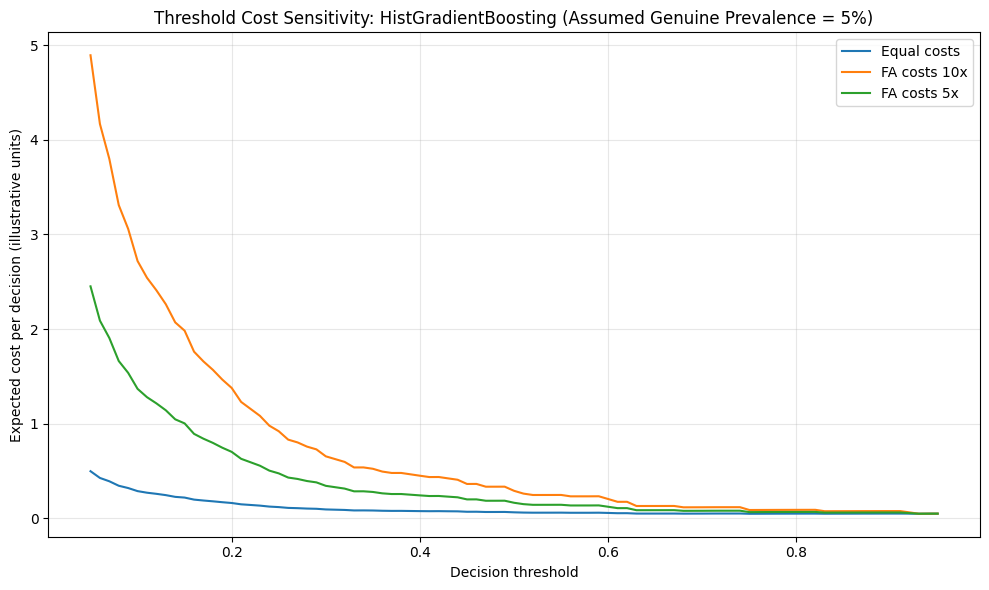

Saved cost curves: /content/DS_A4/raw_results/threshold_cost_curves.png
Saved full threshold analysis: /content/DS_A4/raw_results/threshold_cost_sensitivity.csv
Saved decision record: /content/DS_A4/raw_results/threshold_decision_record.csv

IMPORTANT: This is exploratory threshold analysis using pooled held-out predictions. The same predictions are used to select and evaluate thresholds, so the selected costs are optimistic. Do not treat these thresholds as validated deployment settings.


In [22]:

# STEP 9A: Threshold selection and cost sensitivity analysis

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

BASE_DIR = "/content/DS_A4"
RESULTS_DIR = os.path.join(BASE_DIR, "raw_results")

pred_path = os.path.join(RESULTS_DIR, "model_predictions.csv")
assert os.path.exists(pred_path), f"Missing file: {pred_path}"

pred = pd.read_csv(pred_path)

required = {"model", "y_true", "probability"}
assert required.issubset(pred.columns), (
    f"Missing columns: {required - set(pred.columns)}"
)

# Illustrative deployment scenarios.
# Genuine prevalence is varied because the test set prevalence
# (46.67%) may not represent a real deployment environment.
prevalence_scenarios = [0.01, 0.05, 0.10, 0.50]

# Cost of a false accept relative to a false reject.
cost_scenarios = [
    {"name": "Equal costs", "C_FA": 1.0, "C_FR": 1.0},
    {"name": "FA costs 5x", "C_FA": 5.0, "C_FR": 1.0},
    {"name": "FA costs 10x", "C_FA": 10.0, "C_FR": 1.0},
]

thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)

rows = []

for model_name, group in pred.groupby("model"):
    y = group["y_true"].astype(int).to_numpy()
    p = group["probability"].to_numpy()

    # Require both classes for meaningful FAR and FRR.
    if len(np.unique(y)) != 2:
        continue

    for threshold in thresholds:
        y_hat = (p >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y, y_hat, labels=[0, 1]
        ).ravel()

        far = fp / (fp + tn) if (fp + tn) else np.nan
        frr = fn / (fn + tp) if (fn + tp) else np.nan

        for prevalence in prevalence_scenarios:
            for scenario in cost_scenarios:
                # Expected cost per decision under the assumed
                # genuine-pair prevalence.
                expected_cost = (
                    (1 - prevalence) * scenario["C_FA"] * far
                    + prevalence * scenario["C_FR"] * frr
                )

                rows.append({
                    "model": model_name,
                    "threshold": threshold,
                    "assumed_genuine_prevalence": prevalence,
                    "cost_scenario": scenario["name"],
                    "C_FA": scenario["C_FA"],
                    "C_FR": scenario["C_FR"],
                    "FAR": far,
                    "FRR": frr,
                    "expected_cost_per_decision": expected_cost,
                    "FP": int(fp),
                    "FN": int(fn),
                    "TP": int(tp),
                    "TN": int(tn),
                })

cost_results = pd.DataFrame(rows)

# Find the minimum-cost threshold for each scenario.
best_thresholds = (
    cost_results.sort_values("expected_cost_per_decision")
    .groupby(
        ["model", "assumed_genuine_prevalence", "cost_scenario"],
        as_index=False
    )
    .first()
)

cost_path = os.path.join(
    RESULTS_DIR, "threshold_cost_sensitivity.csv"
)
best_path = os.path.join(
    RESULTS_DIR, "threshold_decision_record.csv"
)

cost_results.to_csv(cost_path, index=False)
best_thresholds.to_csv(best_path, index=False)

print("Minimum-cost thresholds under each assumed scenario:")
display(
    best_thresholds[
        [
            "model",
            "assumed_genuine_prevalence",
            "cost_scenario",
            "threshold",
            "FAR",
            "FRR",
            "expected_cost_per_decision"
        ]
    ].round(4)
)

# Plot cost curves for HistGradientBoosting at 5% assumed prevalence.
plot_model = "HistGradientBoosting"
plot_prevalence = 0.05

plot_data = cost_results[
    (cost_results["model"] == plot_model)
    & (
        cost_results["assumed_genuine_prevalence"]
        == plot_prevalence
    )
]

if not plot_data.empty:
    plt.figure(figsize=(10, 6))

    for scenario_name, group in plot_data.groupby("cost_scenario"):
        group = group.sort_values("threshold")
        plt.plot(
            group["threshold"],
            group["expected_cost_per_decision"],
            label=scenario_name
        )

    plt.xlabel("Decision threshold")
    plt.ylabel("Expected cost per decision (illustrative units)")
    plt.title(
        "Threshold Cost Sensitivity: HistGradientBoosting "
        "(Assumed Genuine Prevalence = 5%)"
    )
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    figure_path = os.path.join(
        RESULTS_DIR, "threshold_cost_curves.png"
    )
    plt.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()

    print(f"Saved cost curves: {figure_path}")

print(f"Saved full threshold analysis: {cost_path}")
print(f"Saved decision record: {best_path}")

print(
    "\nIMPORTANT: This is exploratory threshold analysis using "
    "pooled held-out predictions. The same predictions are used "
    "to select and evaluate thresholds, so the selected costs "
    "are optimistic. Do not treat these thresholds as validated "
    "deployment settings."
)


**Human-review capacity analysis**

In [23]:

# STEP 9B: Human-review capacity sensitivity analysis

import os
import numpy as np
import pandas as pd

BASE_DIR = "/content/DS_A4"
RESULTS_DIR = os.path.join(BASE_DIR, "raw_results")

pred_path = os.path.join(RESULTS_DIR, "model_predictions.csv")
pred = pd.read_csv(pred_path)

model_name = "HistGradientBoosting"
df = pred[pred["model"] == model_name].copy()

assert not df.empty, f"Model not found: {model_name}"

df["y_true"] = df["y_true"].astype(int)
df["probability"] = pd.to_numeric(df["probability"])

# Lower uncertainty distance means closer to probability 0.5.
df["uncertainty"] = (df["probability"] - 0.5).abs()

# Baseline binary prediction at threshold 0.5.
df["baseline_prediction"] = (df["probability"] >= 0.5).astype(int)
df["baseline_error"] = (
    df["baseline_prediction"] != df["y_true"]
).astype(int)

rows = []

for capacity in [0.05, 0.10, 0.20]:
    reviewed_n = int(np.ceil(capacity * len(df)))

    # Review the most uncertain pairs.
    reviewed_idx = df.nsmallest(
        reviewed_n, "uncertainty"
    ).index

    reviewed = df.loc[reviewed_idx]
    automatic = df.drop(index=reviewed_idx)

    # Illustrative oracle-review scenario:
    # assume a human resolves every reviewed case correctly.
    errors_before = int(df["baseline_error"].sum())
    errors_after = int(automatic["baseline_error"].sum())

    rows.append({
        "model": model_name,
        "review_capacity": capacity,
        "total_pairs": len(df),
        "pairs_reviewed": len(reviewed),
        "actual_review_fraction": len(reviewed) / len(df),
        "baseline_errors": errors_before,
        "errors_remaining_after_ideal_review": errors_after,
        "errors_prevented_if_review_is_correct": (
            errors_before - errors_after
        ),
        "reviewed_genuine_pairs": int(
            reviewed["y_true"].sum()
        ),
        "reviewed_impostor_pairs": int(
            (reviewed["y_true"] == 0).sum()
        ),
        "mean_reviewed_uncertainty": reviewed["uncertainty"].mean()
    })

review_results = pd.DataFrame(rows)

out_path = os.path.join(
    RESULTS_DIR, "human_review_capacity_analysis.csv"
)
review_results.to_csv(out_path, index=False)

print("Human-review capacity results:")
display(review_results.round(4))

print(f"\nSaved to: {out_path}")
print(
    "\nIMPORTANT: This is an idealized upper-bound simulation. "
    "It assumes human review resolves every reviewed pair correctly. "
    "Actual human-review performance has not been measured."
)


Human-review capacity results:


,model,review_capacity,total_pairs,pairs_reviewed,actual_review_fraction,baseline_errors,errors_remaining_after_ideal_review,errors_prevented_if_review_is_correct,reviewed_genuine_pairs,reviewed_impostor_pairs,mean_reviewed_uncertainty
0,HistGradientBoosting,0.05,1200,60,0.05,440,408,32,46,14,0.0387
1,HistGradientBoosting,0.10,1200,120,0.10,440,373,67,92,28,0.0766
2,HistGradientBoosting,0.20,1200,240,0.20,440,321,119,172,68,0.1466



Saved to: /content/DS_A4/raw_results/human_review_capacity_analysis.csv

IMPORTANT: This is an idealized upper-bound simulation. It assumes human review resolves every reviewed pair correctly. Actual human-review performance has not been measured.


**Compare datasets and identify model failures**

In [24]:

# STEP 10A: Dataset-level evaluation and failure analysis

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    accuracy_score
)

BASE_DIR = "/content/DS_A4"
RESULTS_DIR = os.path.join(BASE_DIR, "raw_results")

pred_path = os.path.join(RESULTS_DIR, "model_predictions.csv")
pairs_path = os.path.join(BASE_DIR, "all_pairs_corrected_folds.csv")

assert os.path.exists(pred_path), f"Missing: {pred_path}"
assert os.path.exists(pairs_path), f"Missing: {pairs_path}"

pred = pd.read_csv(pred_path)
meta = pd.read_csv(pairs_path)

# Attach pair metadata using the original row order.
# This preserves the connection to the original pair manifest.
if "row_index" not in pred.columns:
    raise ValueError(
        "Predictions have no row_index column. "
        "Please share pred.columns.tolist() so we can align rows safely."
    )

meta = meta.reset_index(drop=True).copy()
meta["row_index"] = np.arange(len(meta))

# Add identity and image-path metadata when available.
candidate_cols = [
    "row_index", "identity_a", "identity_b",
    "image_a", "image_b", "path_a", "path_b",
    "image_path_a", "image_path_b"
]
available_cols = [c for c in candidate_cols if c in meta.columns]

# Do not overwrite columns already present in predictions.
add_cols = [
    c for c in available_cols
    if c == "row_index" or c not in pred.columns
]
meta_small = meta[add_cols].copy()

df = pred.merge(
    meta_small,
    on="row_index",
    how="left",
    validate="many_to_one"
)

assert df["dataset"].notna().all(), (
    "Dataset metadata is missing. Check row_index alignment."
)
assert df["y_true"].notna().all()
assert df["probability"].notna().all()

df["y_true"] = df["y_true"].astype(int)
df["prediction"] = (df["probability"] >= 0.5).astype(int)
df["error"] = df["prediction"] != df["y_true"]

# 1. Evaluate each model separately on each dataset.
rows = []

for (model, dataset), g in df.groupby(["model", "dataset"]):
    y = g["y_true"].to_numpy()
    p = g["probability"].to_numpy()
    yh = g["prediction"].to_numpy()

    tn = int(((y == 0) & (yh == 0)).sum())
    fp = int(((y == 0) & (yh == 1)).sum())
    fn = int(((y == 1) & (yh == 0)).sum())
    tp = int(((y == 1) & (yh == 1)).sum())

    rows.append({
        "model": model,
        "dataset": dataset,
        "n_pairs": len(g),
        "genuine_pairs": int((y == 1).sum()),
        "impostor_pairs": int((y == 0).sum()),
        "accuracy_at_0_5": accuracy_score(y, yh),
        "roc_auc": (
            roc_auc_score(y, p) if len(np.unique(y)) == 2
            else np.nan
        ),
        "average_precision": average_precision_score(y, p),
        "brier_score": brier_score_loss(y, p),
        "FAR": fp / (fp + tn) if fp + tn else np.nan,
        "FRR": fn / (fn + tp) if fn + tp else np.nan,
        "false_accepts": fp,
        "false_rejects": fn,
        "total_errors": fp + fn
    })

slice_summary = pd.DataFrame(rows).sort_values(
    ["model", "dataset"]
)

slice_path = os.path.join(
    RESULTS_DIR, "dataset_slice_metrics.csv"
)
slice_summary.to_csv(slice_path, index=False)

print("Performance by model and dataset:")
display(slice_summary.round(4))

# 2. Inspect the most confident errors for HistGradientBoosting.
model_name = "HistGradientBoosting"
failures = df[
    (df["model"] == model_name) & df["error"]
].copy()

# Confidence in the incorrect predicted class.
failures["wrong_class_confidence"] = np.where(
    failures["prediction"] == 1,
    failures["probability"],
    1 - failures["probability"]
)

failures["failure_type"] = np.where(
    failures["y_true"] == 0,
    "False accept: impostor predicted genuine",
    "False reject: genuine predicted impostor"
)

# Show useful metadata columns only when they exist.
display_cols = [
    c for c in [
        "dataset", "identity_a", "identity_b",
        "row_index", "failure_type", "y_true",
        "probability", "wrong_class_confidence",
        "image_a", "image_b", "path_a", "path_b",
        "image_path_a", "image_path_b"
    ]
    if c in failures.columns
]

top_failures = failures.sort_values(
    "wrong_class_confidence", ascending=False
)[display_cols].head(20)

failure_path = os.path.join(
    RESULTS_DIR, "top_model_failures.csv"
)
top_failures.to_csv(failure_path, index=False)

print("\nMost confident HistGradientBoosting errors:")
display(top_failures)

print(f"\nSaved dataset metrics: {slice_path}")
print(f"Saved failure cases: {failure_path}")
print(
    "\nInterpretation note: these are exploratory slices. "
    "The available held-out pairs cover only a subset of possible "
    "impostor identity combinations, so avoid broad generalization."
)


Performance by model and dataset:


,model,dataset,n_pairs,genuine_pairs,impostor_pairs,accuracy_at_0_5,roc_auc,average_precision,brier_score,FAR,FRR,false_accepts,false_rejects,total_errors
0,DummyPrior,DB1_B,600,280,320,0.5333,0.5000,0.4667,0.3753,0.0000,1.0000,0,280,280
1,DummyPrior,DB2_B,600,280,320,0.5333,0.5000,0.4667,0.3753,0.0000,1.0000,0,280,280
2,HistGradientBoosting,DB1_B,600,280,320,0.6467,0.7626,0.7570,0.2638,0.0281,0.7250,9,203,212
3,HistGradientBoosting,DB2_B,600,280,320,0.6200,0.7333,0.7471,0.2944,0.0250,0.7857,8,220,228
4,LogisticRegression,DB1_B,600,280,320,0.6050,0.7578,0.7442,0.2813,0.0062,0.8393,2,235,237
5,LogisticRegression,DB2_B,600,280,320,0.5850,0.7270,0.7515,0.2997,0.0000,0.8893,0,249,249
6,RandomForest,DB1_B,600,280,320,0.6600,0.7335,0.7425,0.2619,0.0312,0.6929,10,194,204
7,RandomForest,DB2_B,600,280,320,0.6300,0.7089,0.7280,0.2898,0.0281,0.7607,9,213,222



Most confident HistGradientBoosting errors:


,dataset,identity_a,identity_b,row_index,failure_type,y_true,probability,wrong_class_confidence,path_a,path_b
4576,DB1_B,104,104,100,False reject: genuine predicted impostor,1,0.001283,0.998717,/content/DS_A4/data/extracted/DB1_B/104_3.tif,/content/DS_A4/data/extracted/DB1_B/104_7.tif
3604,DB1_B,105,105,116,False reject: genuine predicted impostor,1,0.001407,0.998593,/content/DS_A4/data/extracted/DB1_B/105_1.tif,/content/DS_A4/data/extracted/DB1_B/105_6.tif
3609,DB1_B,105,105,121,False reject: genuine predicted impostor,1,0.001425,0.998575,/content/DS_A4/data/extracted/DB1_B/105_2.tif,/content/DS_A4/data/extracted/DB1_B/105_5.tif
857,DB2_B,102,102,3205,False reject: genuine predicted impostor,1,0.001588,0.998412,/content/DS_A4/data/extracted/DB2_B/102_3.tif,/content/DS_A4/data/extracted/DB2_B/102_8.tif
852,DB2_B,102,102,3200,False reject: genuine predicted impostor,1,0.001611,0.998389,/content/DS_A4/data/extracted/DB2_B/102_2.tif,/content/DS_A4/data/extracted/DB2_B/102_8.tif
864,DB2_B,102,102,3212,False reject: genuine predicted impostor,1,0.001748,0.998252,/content/DS_A4/data/extracted/DB2_B/102_5.tif,/content/DS_A4/data/extracted/DB2_B/102_8.tif
846,DB2_B,102,102,3194,False reject: genuine predicted impostor,1,0.001940,0.998060,/content/DS_A4/data/extracted/DB2_B/102_1.tif,/content/DS_A4/data/extracted/DB2_B/102_8.tif
3614,DB1_B,105,105,126,False reject: genuine predicted impostor,1,0.002193,0.997807,/content/DS_A4/data/extracted/DB1_B/105_3.tif,/content/DS_A4/data/extracted/DB1_B/105_5.tif
867,DB2_B,102,102,3215,False reject: genuine predicted impostor,1,0.002228,0.997772,/content/DS_A4/data/extracted/DB2_B/102_7.tif,/content/DS_A4/data/extracted/DB2_B/102_8.tif
3615,DB1_B,105,105,127,False reject: genuine predicted impostor,1,0.002550,0.997450,/content/DS_A4/data/extracted/DB1_B/105_3.tif,/content/DS_A4/data/extracted/DB1_B/105_6.tif



Saved dataset metrics: /content/DS_A4/raw_results/dataset_slice_metrics.csv
Saved failure cases: /content/DS_A4/raw_results/top_model_failures.csv

Interpretation note: these are exploratory slices. The available held-out pairs cover only a subset of possible impostor identity combinations, so avoid broad generalization.


**Visually inspect representative failure cases**

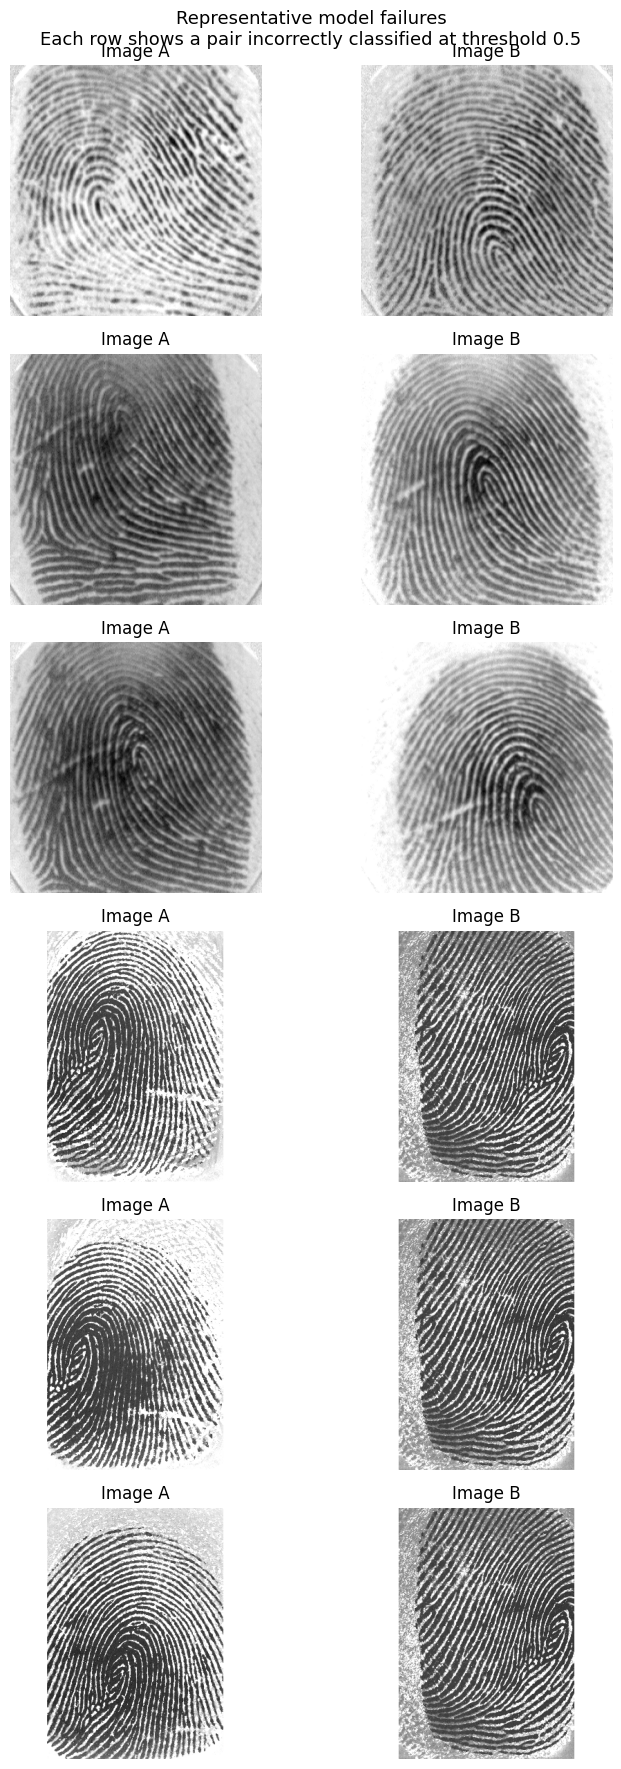

Interpretation checklist:
1. Are the images blurred, noisy, or poorly contrasted?
2. Are ridge patterns visibly different in the same-identity pair?
3. Are there obvious cropping or alignment differences?
4. Record observations; do not infer the cause from one pair alone.


In [25]:

# STEP 10B: Visual inspection of representative failure cases

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

BASE_DIR = "/content/DS_A4"
RESULTS_DIR = os.path.join(BASE_DIR, "raw_results")

failure_path = os.path.join(
    RESULTS_DIR, "top_model_failures.csv"
)
assert os.path.exists(failure_path), (
    f"Missing failure file: {failure_path}"
)

failures = pd.read_csv(failure_path)

required = {
    "dataset", "failure_type", "probability",
    "wrong_class_confidence", "path_a", "path_b"
}
missing = required - set(failures.columns)
assert not missing, f"Missing columns: {missing}"

# Select up to six representative errors.
# Keep examples from both datasets when available.
selected = []
for dataset in failures["dataset"].dropna().unique():
    selected.extend(
        failures[failures["dataset"] == dataset].head(3).to_dict("records")
    )

selected = selected[:6]

fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(8, 3 * len(selected))
)

if len(selected) == 1:
    axes = [axes]

for i, row in enumerate(selected):
    ax_a, ax_b = axes[i]

    for ax, path, label in [
        (ax_a, row["path_a"], "Image A"),
        (ax_b, row["path_b"], "Image B")
    ]:
        if isinstance(path, str) and os.path.exists(path):
            with Image.open(path) as img:
                ax.imshow(img.convert("L"), cmap="gray")
            ax.set_title(label)
        else:
            ax.text(
                0.5, 0.5, f"Image not found:\n{path}",
                ha="center", va="center", wrap=True
            )
            ax.set_title(label)

        ax.axis("off")

    fig.suptitle(
        "Representative model failures\n"
        "Each row shows a pair incorrectly classified at threshold 0.5",
        fontsize=13
    )

    ax_a.set_ylabel(
        f"{row['dataset']}\n{row['failure_type']}\n"
        f"P(genuine)={row['probability']:.4f}",
        fontsize=8
    )

plt.tight_layout()
plt.show()

print("Interpretation checklist:")
print("1. Are the images blurred, noisy, or poorly contrasted?")
print("2. Are ridge patterns visibly different in the same-identity pair?")
print("3. Are there obvious cropping or alignment differences?")
print("4. Record observations; do not infer the cause from one pair alone.")


**Statistical uncertainty and record limitations**

In [26]:

# STEP 11A: Check uncertainty results and document limitations

import os
import pandas as pd

BASE_DIR = "/content/DS_A4"
RESULTS_DIR = os.path.join(BASE_DIR, "raw_results")

bootstrap_path = os.path.join(
    RESULTS_DIR, "roc_auc_cluster_bootstrap.csv"
)

if os.path.exists(bootstrap_path):
    bootstrap = pd.read_csv(bootstrap_path)

    print("Bootstrap results found:")
    display(bootstrap.head(20))

    print("\nColumns:", bootstrap.columns.tolist())
else:
    print("Bootstrap results not found.")
    print("We must complete or rerun Step 8B before finalizing uncertainty.")

# Record limitations based on the completed evaluation.
limitations = [
    {
        "issue": "Small identity sample",
        "limitation": (
            "Only 20 dataset-specific identities are available: "
            "10 in DB1_B and 10 in DB2_B."
        ),
        "implication": (
            "Results may not generalize to unseen populations or "
            "different fingerprint acquisition conditions."
        )
    },
    {
        "issue": "Incomplete impostor-pair coverage",
        "limitation": (
            "The held-out evaluation includes only impostor pairs "
            "whose identities belong to the same held-out fold."
        ),
        "implication": (
            "Pooled metrics do not represent every possible impostor "
            "identity combination."
        )
    },
    {
        "issue": "Genuine-pair prevalence",
        "limitation": (
            "The held-out set contains 560 genuine and 640 impostor "
            "pairs, giving a genuine-pair proportion of 46.67%."
        ),
        "implication": (
            "Calibration, precision, and threshold costs may change "
            "under a different deployment prevalence."
        )
    },
    {
        "issue": "Simple handcrafted features",
        "limitation": (
            "The models use mean absolute pixel difference, pixel "
            "correlation, SSIM, and a dataset indicator."
        ),
        "implication": (
            "The comparison does not establish the performance of "
            "specialized fingerprint-matching neural networks."
        )
    },
    {
        "issue": "Threshold selection",
        "limitation": (
            "Thresholds were selected using pooled held-out predictions "
            "also used to calculate their apparent costs."
        ),
        "implication": (
            "The minimum-cost values are exploratory and require "
            "independent validation before deployment."
        )
    },
    {
        "issue": "Human-review simulation",
        "limitation": (
            "The review analysis assumes reviewed cases are resolved "
            "correctly; actual reviewer performance was not measured."
        ),
        "implication": (
            "Reported error reductions are idealized upper bounds."
        )
    }
]

limitations_path = os.path.join(
    RESULTS_DIR, "limitations_record.csv"
)

pd.DataFrame(limitations).to_csv(
    limitations_path, index=False
)

print(f"\nSaved limitations record: {limitations_path}")


Bootstrap results found:


,model,pooled_oof_roc_auc,bootstrap_95_ci_low,bootstrap_95_ci_high,valid_bootstrap_replicates
0,DummyPrior,0.500000,0.500000,0.500000,1000
1,HistGradientBoosting,0.752323,0.592323,0.890731,998
2,LogisticRegression,0.743730,0.542121,0.914633,1000
3,RandomForest,0.724280,0.574504,0.855873,999



Columns: ['model', 'pooled_oof_roc_auc', 'bootstrap_95_ci_low', 'bootstrap_95_ci_high', 'valid_bootstrap_replicates']

Saved limitations record: /content/DS_A4/raw_results/limitations_record.csv


#**The final report and reproducibility documentation**

In [27]:

# STEP 12A: Generate report and reproducibility documentation

import os
import sys
import platform
import subprocess
import pandas as pd
import sklearn
import numpy as np

BASE_DIR = "/content/DS_A4"
RESULTS_DIR = os.path.join(BASE_DIR, "raw_results")
DOCS_DIR = os.path.join(BASE_DIR, "documentation")
os.makedirs(DOCS_DIR, exist_ok=True)

# Load actual saved results.
summary = pd.read_csv(
    os.path.join(RESULTS_DIR, "pooled_oof_summary.csv")
)
slices = pd.read_csv(
    os.path.join(RESULTS_DIR, "dataset_slice_metrics.csv")
)
limitations = pd.read_csv(
    os.path.join(RESULTS_DIR, "limitations_record.csv")
)

# Format results tables from the actual CSVs.
summary_md = summary.round(4).to_markdown(index=False)
slices_md = slices.round(4).to_markdown(index=False)
limitations_md = limitations.to_markdown(index=False)

# Environment information.
environment = f"""
- Python: {sys.version.split()[0]}
- Platform: {platform.platform()}
- NumPy: {np.__version__}
- pandas: {pd.__version__}
- scikit-learn: {sklearn.__version__}
- Random seed used in identity-fold assignment: 42
"""

report = f"""# DS-A4: Model Comparison and Calibration Lab

## 1. Objective

Compare a simple baseline with logistic regression, random forest, and
histogram-based gradient boosting for fingerprint-pair verification.
The task is to distinguish genuine pairs (label 1) from impostor pairs
(label 0), compare ranking and probability quality, explore decision
thresholds, and inspect model failures.

## 2. Data and protocol

The experiment uses the DB1_B and DB2_B fingerprint image subsets.
The manifest contains 160 images across 20 dataset-specific identities.
Pairs are evaluated using the corrected identity-fold assignment.
For each held-out fold, training pairs have neither identity held out;
test pairs have both identities in the held-out fold; pairs crossing
the train/test identity boundary are excluded.

The pooled out-of-fold predictions cover 1,200 pairs per model.
The held-out set contains 560 genuine and 640 impostor pairs.

## 3. Models

- DummyPrior: simple prior-probability baseline.
- LogisticRegression: standardized linear baseline.
- RandomForest: tree ensemble.
- HistGradientBoosting: gradient-boosted tree model.

Pair features are mean absolute pixel difference, pixel correlation,
structural similarity (SSIM), and a dataset indicator. Images are
resized to 64 × 64 grayscale for feature extraction.

## 4. Pooled out-of-fold results

{summary_md}

ROC-AUC measures ranking ability; average precision summarizes
precision-recall performance; Brier score measures squared probability
error, where lower is better. These metrics are descriptive of the
available held-out pairs and should not be assumed to represent a
deployment population.

## 5. Dataset-level results

{slices_md}

HistGradientBoosting achieved ROC-AUC 0.7626 on DB1_B and 0.7333 on
DB2_B. The difference suggests dataset-dependent performance in this
evaluation, but the small number of identities limits generalization.

At threshold 0.5, false rejects are common. The current handcrafted
features and models therefore do not yet provide sufficiently reliable
genuine-pair verification at that threshold.

## 6. Threshold and human-review analysis

Threshold cost sensitivity was explored under illustrative genuine-pair
prevalences of 1%, 5%, 10%, and 50%, and illustrative false-accept cost
ratios of 1:1, 5:1, and 10:1 relative to false rejects.

Human-review capacities of 5%, 10%, and 20% were simulated by selecting
the predictions closest to probability 0.5. The simulation assumes all
reviewed cases are resolved correctly, so error reductions are idealized
upper bounds, not measured human performance.

Thresholds were selected and evaluated using the same pooled held-out
predictions. Consequently, the reported minimum costs are exploratory
and optimistic; a final threshold should be selected on a separate,
identity-disjoint validation set.

## 7. Failure analysis

Representative false rejects were inspected visually. Some pairs show
differences in contrast, orientation, cropping, image quality, or visible
ridge detail. These observations are hypotheses for investigation, not
proven causes of model failure.

## 8. Uncertainty and limitations

{limitations_md}

The exploratory identity-cluster bootstrap produced wide, overlapping
ROC-AUC intervals for the learned models. It does not establish that one
learned model is statistically superior to another. The small identity
sample and incomplete impostor identity-pair coverage are major
limitations. The current results should not be presented as validated
deployment performance.

## 9. Environment

{environment}

## 10. Conclusion

HistGradientBoosting has the highest pooled ROC-AUC in this experiment,
with logistic regression close behind. However, uncertainty is substantial,
false rejects are frequent at threshold 0.5, and calibration and threshold
decisions are sensitive to the assumed deployment prevalence and costs.
The results support a reproducible preliminary comparison, not a claim of
deployment readiness.

## 11. Reproducibility checklist

- [ ] Restart the runtime and run the notebook from top to bottom.
- [ ] Confirm the data manifests and all saved outputs are present.
- [ ] Verify dependency versions and seeds.
- [ ] Keep failed runs and negative results.
- [ ] Review every result and report statement independently.
- [ ] Commit the notebook, source, report, raw results, and AI-use log.
- [ ] Replace the GitHub URL placeholder with the final repository and
      commit or tag URL.
"""

readme = """# DS-A4 Model Comparison and Calibration Lab

## Overview
Fingerprint-pair verification using DB1_B and DB2_B, handcrafted pair
features, four classifiers, out-of-fold evaluation, calibration metrics,
threshold cost sensitivity, human-review simulation, and failure analysis.

## Main artifacts
- `verified_image_manifest.csv`
- `all_pairs_corrected_folds.csv`
- `identity_folds.csv`
- `pair_features.csv`
- `raw_results/model_predictions.csv`
- `raw_results/fold_metrics.csv`
- `raw_results/pooled_oof_summary.csv`
- `raw_results/roc_auc_cluster_bootstrap.csv`
- `raw_results/threshold_cost_sensitivity.csv`
- `raw_results/threshold_decision_record.csv`
- `raw_results/human_review_capacity_analysis.csv`
- `raw_results/dataset_slice_metrics.csv`
- `raw_results/top_model_failures.csv`
- `raw_results/limitations_record.csv`
- `documentation/final_report.md`
- `documentation/frozen_protocol.md`
- `documentation/AI_USE_LOG.md`

## Reproduction
Open the notebook in Google Colab, ensure the input archives are available,
and execute the notebook from the first cell to the last. Record the
runtime, package versions, random seeds, and data version.

## Important limitations
Only 20 dataset-specific identities are available. Test pairs cover a
subset of possible impostor identity combinations. Threshold costs and
human-review reductions are exploratory assumptions, not deployment
validation.

## Repository
GitHub URL: ADD_FINAL_REPOSITORY_URL
Commit/tag: ADD_FINAL_COMMIT_OR_TAG
"""

protocol = """# Frozen Experimental Protocol

## Data
- Dataset subsets: DB1_B and DB2_B.
- Images: 160 total, 80 per subset.
- Identities: 10 per subset; identities must be treated as dataset-specific.
- Pair labels: 1 = genuine (same identity), 0 = impostor (different identities).
- Image preprocessing: grayscale resize to 64 × 64.

## Identity folds
- Five identity folds per dataset.
- Random seed: 42.
- Train: neither pair identity is in the held-out fold.
- Test: both pair identities are in the held-out fold.
- Excluded: exactly one pair identity is in the held-out fold.

## Features
- Mean absolute pixel difference.
- Pixel correlation.
- Structural similarity (SSIM).
- Dataset indicator (`dataset_DB2_B`).

## Models
- DummyClassifier(strategy='prior').
- StandardScaler + LogisticRegression(max_iter=2000, random_state=42).
- RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
  random_state=42, n_jobs=-1).
- HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08,
  max_leaf_nodes=15, l2_regularization=1, random_state=42).

## Metrics
- Accuracy at threshold 0.5.
- ROC-AUC.
- Average precision.
- Brier score.
- Expected calibration error, as implemented in the notebook.
- FAR and FRR for threshold analysis.

## Decision analysis
- Threshold grid: 0.05 to 0.95 in increments of 0.01.
- Assumed genuine prevalence: 1%, 5%, 10%, 50%.
- False-accept to false-reject cost ratios: 1:1, 5:1, 10:1.
- Human review capacity: 5%, 10%, 20%; review prioritizes probabilities
  closest to 0.5 and assumes perfect review only as an idealized upper bound.

## Known limitations
- Only 20 dataset-specific identities.
- Incomplete impostor identity-pair coverage in held-out evaluation.
- Thresholds are selected on the same pooled predictions used for
  exploratory cost calculation.
- Human-review performance is simulated, not measured.
- Bootstrap intervals are exploratory and should not be interpreted as
  definitive evidence of model superiority.

Any deviation from this protocol must be documented before results are
interpreted. Preserve failed runs and negative results.
"""

ai_log = """# AI Use Log

## Tool used
ChatGPT was used as an assistant during notebook development and analysis.

## Assistance provided
- Suggested and debugged Python/Colab code for pair construction,
  feature extraction, model comparison, evaluation, plotting, threshold
  sensitivity, review-capacity simulation, and documentation.
- Helped interpret metrics and identify limitations in the evaluation.
- Helped draft report and reproducibility documentation.

## Human responsibilities
The project author must independently inspect and verify all code,
dataset assumptions, output tables, plots, interpretations, and report
claims before submission. No result should be reported unless it was
actually produced by the executed notebook. The author should edit this
log to accurately reflect all AI tools used and the assistance received.

## Verification status
Pending final clean-runtime execution and independent review.
"""

files_to_write = {
    os.path.join(DOCS_DIR, "final_report.md"): report,
    os.path.join(BASE_DIR, "README.md"): readme,
    os.path.join(DOCS_DIR, "frozen_protocol.md"): protocol,
    os.path.join(DOCS_DIR, "AI_USE_LOG.md"): ai_log,
}

for path, content in files_to_write.items():
    with open(path, "w", encoding="utf-8") as f:
        f.write(content.strip() + "\n")
    print("Created:", path)

print("\nDocumentation generated.")
print("Review the report and verify all claims before submission.")


Created: /content/DS_A4/documentation/final_report.md
Created: /content/DS_A4/README.md
Created: /content/DS_A4/documentation/frozen_protocol.md
Created: /content/DS_A4/documentation/AI_USE_LOG.md

Documentation generated.
Review the report and verify all claims before submission.


In [28]:

# STEP 12B: Verify required artifacts and create submission ZIP

import os
import zipfile
import pandas as pd
from pathlib import Path

BASE_DIR = Path("/content/DS_A4")
RESULTS_DIR = BASE_DIR / "raw_results"
DOCS_DIR = BASE_DIR / "documentation"

required_files = [
    "verified_image_manifest.csv",
    "identity_folds.csv",
    "all_pairs_corrected_folds.csv",
    "pair_features.csv",
    "README.md",
    "raw_results/model_predictions.csv",
    "raw_results/fold_metrics.csv",
    "raw_results/pooled_oof_summary.csv",
    "raw_results/roc_auc_cluster_bootstrap.csv",
    "raw_results/threshold_cost_sensitivity.csv",
    "raw_results/threshold_decision_record.csv",
    "raw_results/human_review_capacity_analysis.csv",
    "raw_results/dataset_slice_metrics.csv",
    "raw_results/top_model_failures.csv",
    "raw_results/limitations_record.csv",
    "documentation/final_report.md",
    "documentation/frozen_protocol.md",
    "documentation/AI_USE_LOG.md",
]

checks = []

for relative_path in required_files:
    full_path = BASE_DIR / relative_path
    checks.append({
        "file": relative_path,
        "exists": full_path.is_file(),
        "size_bytes": full_path.stat().st_size if full_path.is_file() else None
    })

check_df = pd.DataFrame(checks)

print("Required artifact check:")
display(check_df)

missing = check_df.loc[~check_df["exists"], "file"].tolist()

# Check plots separately because filenames may vary if earlier cells
# used different output names.
plot_files = sorted(RESULTS_DIR.glob("*.png"))
print("\nPlots found:")
for p in plot_files:
    print("-", p.relative_to(BASE_DIR))

# Discover notebook files in the project.
notebooks = sorted(BASE_DIR.rglob("*.ipynb"))
print("\nNotebook files found:")
for p in notebooks:
    print("-", p.relative_to(BASE_DIR))

if missing:
    print("\nMISSING REQUIRED FILES:")
    for name in missing:
        print("-", name)
    print("\nDo not submit yet. We need to restore or regenerate these files.")
else:
    print("\nAll listed required files are present.")

# Write a simple dependency record for reproducibility.
try:
    import sklearn, numpy, pandas, skimage, PIL
    requirements = [
        f"numpy=={numpy.__version__}",
        f"pandas=={pandas.__version__}",
        f"scikit-learn=={sklearn.__version__}",
        f"scikit-image=={skimage.__version__}",
        f"Pillow=={PIL.__version__}",
    ]
    (BASE_DIR / "requirements.txt").write_text(
        "\n".join(requirements) + "\n",
        encoding="utf-8"
    )
    print("\nCreated requirements.txt")
except Exception as e:
    print("\nCould not create complete requirements.txt:", e)

# Create a ZIP only when the required files exist.
if not missing:
    zip_path = Path("/content/DS_A4_submission.zip")

    with zipfile.ZipFile(
        zip_path, "w", compression=zipfile.ZIP_DEFLATED
    ) as zf:
        for path in BASE_DIR.rglob("*"):
            if not path.is_file():
                continue
            # Avoid temporary notebook checkpoints.
            if ".ipynb_checkpoints" in path.parts:
                continue
            zf.write(path, path.relative_to(BASE_DIR.parent))

    print(f"\nSubmission ZIP created: {zip_path}")
    print(f"ZIP size: {zip_path.stat().st_size / (1024 * 1024):.2f} MB")
else:
    print("\nZIP not created because required files are missing.")


Required artifact check:


,file,exists,size_bytes
0,verified_image_manifest.csv,True,5166
1,identity_folds.csv,True,262
2,all_pairs_corrected_folds.csv,True,952395
3,pair_features.csv,True,730147
4,README.md,True,1485
5,raw_results/model_predictions.csv,True,250372
6,raw_results/fold_metrics.csv,True,2698
7,raw_results/pooled_oof_summary.csv,True,439
8,raw_results/roc_auc_cluster_bootstrap.csv,True,352
9,raw_results/threshold_cost_sensitivity.csv,True,421362



Plots found:
- raw_results/pr_curves.png
- raw_results/reliability_diagrams.png
- raw_results/roc_curves.png
- raw_results/threshold_cost_curves.png

Notebook files found:

All listed required files are present.

Created requirements.txt

Submission ZIP created: /content/DS_A4_submission.zip
ZIP size: 22.02 MB


In [29]:

from google.colab import files
from pathlib import Path
import shutil

project_dir = Path("/content/DS_A4")
project_dir.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()

notebooks = [
    name for name in uploaded
    if name.endswith(".ipynb")
]

if not notebooks:
    raise ValueError(
        "No .ipynb file uploaded. Download your Colab notebook first."
    )

for name in notebooks:
    destination = project_dir / Path(name).name
    shutil.move(name, destination)
    print(f"Notebook added: {destination}")

print("\nNotebook files now in project:")
for path in project_dir.glob("*.ipynb"):
    print("-", path.name)


KeyboardInterrupt: 